# Smoking-associated gene expression in lung adenocarcinoma (GEO: GSE43458)

## 1. Question and objectives

**Research question**
Are there significant differences in gene expression between lung adenocarcinoma (LUAD) patients who have smoked and those who have never smoked, and which biological processes are associated with these differences?

**Objectives**
1. Identify genes whose expression differs significantly between smokers and never-smokers with lung adenocarcinoma.
2. Determine which biological processes are associated with those genes.
3. Use machine learning as a *supplementary* analysis to investigate whether expression patterns can distinguish the two groups.


**Notebook map**

| Section | Content |
|---|---|
| 1 | Question and objectives |
| 2 | Data acquisition (source documented) |
| 3 | Preprocessing and quality control, including biology sanity checks |
| 4 | Exploratory data analysis |
| 5 | Core analysis: differential expression and pathway enrichment |
| 6 | Biological interpretation |
| 7 | Machine learning (supplementary) |
| 8 | Summary, limitations and export |

**Important design decision.** The values deposited in GEO for GSE43458 were already summarised with RMA and log2-transformed by the original authors.

### Environment setup
- `GEOparse` to download and parse GEO records,
- `gseapy` to run enrichment analysis

In [1]:
!pip install -q GEOparse gseapy

In [2]:
import os, re, json, glob, hashlib, zipfile, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, special
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})

# analysis parameters
SEED = 42                        # reproducibility
np.random.seed(SEED)

FDR_THRESHOLD = 0.05             # Benjamini-Hochberg FDR for calling a gene significant
LOGFC_CUTOFF = 0.30              # |log2 fold change| for the "strong effect" subset (~1.23-fold)
LOW_EXPR_QUANTILE = 0.20         # drop genes whose mean expression is in the lowest 20% (background noise)
N_PERMUTATIONS = int(os.environ.get("N_PERMUTATIONS", 200))   # label permutations for DE calibration
N_PERM_ML = int(os.environ.get("N_PERM_ML", 100))             # label permutations for the ML significance test
RUN_GO_GSEA = False              # GSEA on GO-BP is slow (thousands of terms); set True if you want it

OUTDIR = "results"
os.makedirs(OUTDIR, exist_ok=True)
PALETTE = {"Never": "#2a9d8f", "Smoker": "#e76f51", "Tumor": "#6a4c93", "Normal": "#8d99ae"}
print("Setup complete.")

Setup complete.


## 2. Data acquisition

**Source:** NCBI Gene Expression Omnibus, accession **GSE43458**
URL: <https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE43458>
Study: Kadara *et al.* (Clin Cancer Res, 2013), expression profiling of lung adenocarcinomas and normal lung on the **Affymetrix Human Gene 1.0 ST** array.

GEO describes 110 samples: 80 lung adenocarcinomas (40 smokers, 40 never-smokers) and 30 normal lung tissues. I downloaded the full series record with `GEOparse`, which gives us (i) the processed expression matrix, (ii) per-sample metadata, and (iii) the platform annotation table. The downloaded file's SHA-256 hash and download date are recorded for provenance.

In [3]:
import GEOparse

GSE_ID = "GSE43458"
GEO_URL = f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={GSE_ID}"
os.makedirs("data", exist_ok=True)

gse = GEOparse.get_GEO(geo=GSE_ID, destdir="data", silent=True)

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

soft_files = [f for f in glob.glob(f"data/{GSE_ID}*") if os.path.isfile(f)]
first = lambda key: (gse.metadata.get(key) or [""])[0]

provenance = {
    "accession": GSE_ID,
    "url": GEO_URL,
    "title": first("title"),
    "platform": list(gse.gpls.keys()),
    "n_samples_in_record": len(gse.gsms),
    "submission_date": first("submission_date"),
    "last_update_date": first("last_update_date"),
    "pubmed_id": gse.metadata.get("pubmed_id"),
    "downloaded_on": datetime.date.today().isoformat(),
    "downloaded_files": {f: sha256(f) for f in soft_files},
}
with open(f"{OUTDIR}/data_provenance.json", "w") as fh:
    json.dump(provenance, fh, indent=2)
print(json.dumps(provenance, indent=2))
print("\nSummary:", first("summary")[:600], "...")

{
  "accession": "GSE43458",
  "url": "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE43458",
  "title": "Gene expression profiling of lung adenocarcinomas and normal lung tissue",
  "platform": [
    "GPL6244"
  ],
  "n_samples_in_record": 110,
  "submission_date": "Jan 11 2013",
  "last_update_date": "Jul 26 2018",
  "pubmed_id": [
    "23659968"
  ],
  "downloaded_on": "2026-11-24",
  "downloaded_files": {
    "data/GSE43458_family.soft.gz": "407bd7df3e67ad37408bf556ffdb0194e243162d175329b586e2d3a1896c3009"
  }
}

Summary: Lung cancer is still the leading cause of cancer-related deaths in the US and worldwide. Understanding the global molecular profiles or transcriptome of lung cancers would strengthen our understanding of the biology of this malignancy. ...


### 2.1 Expression matrix and sample metadata
`pivot_samples("VALUE")` returns the deposited (already RMA-normalised, log2) values as a *probe set × sample* table. Each sample's free-text "characteristics" (tissue, smoking status, sex, age, ...) are parsed into columns.

In [4]:
# probe sets x samples (values exactly as deposited; NOT modified here)
expr_probe = gse.pivot_samples("VALUE")
expr_probe.index = expr_probe.index.astype(str)
print("Expression matrix (probe sets x samples):", expr_probe.shape)

# parse the sample metadata
def parse_characteristics(gsm):
    d = {}
    for i, item in enumerate(gsm.metadata.get("characteristics_ch1", [])):
        if ":" in item:
            k, v = item.split(":", 1)
            d[k.strip().lower()] = v.strip()
        else:
            d[f"char_{i}"] = item.strip()
    return d

rows = []
for gsm_id, gsm in gse.gsms.items():
    r = {"gsm": gsm_id,
         "title": (gsm.metadata.get("title") or [""])[0],
         "source_name": (gsm.metadata.get("source_name_ch1") or [""])[0]}
    r.update(parse_characteristics(gsm))
    rows.append(r)
meta = pd.DataFrame(rows).set_index("gsm")

common = [s for s in expr_probe.columns if s in meta.index]
expr_probe = expr_probe[common]
meta = meta.loc[common]
print("Samples with both expression and metadata:", len(common))

display(meta.head())
print("\nMetadata fields and their values (fields with <= 15 distinct values):")
for c in meta.columns:
    if meta[c].nunique() <= 15:
        print(f"\n-- {c}")
        print(meta[c].value_counts(dropna=False).to_string())

Expression matrix (probe sets x samples): (33252, 110)
Samples with both expression and metadata: 110


,title,source_name,tissue,histology,smoking status
gsm,,,,,
GSM1062765,Lung adenocarcinoma tissue from never-smoker_1,Never-smoker lung adenocarcinoma patient,Lung tumor,Lung adenocarcinoma,Never-smoker
GSM1062766,Lung adenocarcinoma tissue from never-smoker_2,Never-smoker lung adenocarcinoma patient,Lung tumor,Lung adenocarcinoma,Never-smoker
GSM1062767,Lung adenocarcinoma tissue from never-smoker_3,Never-smoker lung adenocarcinoma patient,Lung tumor,Lung adenocarcinoma,Never-smoker
GSM1062768,Lung adenocarcinoma tissue from never-smoker_4,Never-smoker lung adenocarcinoma patient,Lung tumor,Lung adenocarcinoma,Never-smoker
GSM1062769,Lung adenocarcinoma tissue from never-smoker_5,Never-smoker lung adenocarcinoma patient,Lung tumor,Lung adenocarcinoma,Never-smoker



Metadata fields and their values (fields with <= 15 distinct values):

-- source_name
source_name
Never-smoker lung adenocarcinoma patient    70
Smoker lung adenocarcinoma patient          40

-- tissue
tissue
Lung tumor            80
Normal lung tissue    30

-- histology
histology
Lung adenocarcinoma    80
Normal lung tissue     30

-- smoking status
smoking status
Never-smoker    70
Smoker          40


## 3. Preprocessing and quality control

1. **Label samples**: tissue (tumour vs normal) and smoking status (smoker vs never-smoker).
2. **Verify the data are already on the log2 scale** and contain no missing values.
3. **Map probe sets to gene symbols** using the GPL6244 annotation, keep only well-annotated "main" probe sets, and collapse several probe sets per gene by keeping the one with the highest mean expression (this *selects* a value; it does not average or rescale anything).
4. **Quality control**: per-sample distributions, sample-to-sample correlation (outliers), and **biological sanity checks** (lineage markers, sex genes, expected tumour-vs-normal directions).
5. **Filter** genes in the lowest expression quantile (background noise).

### 3.1 Label samples
The code below detects tissue and smoking status from the metadata text.

In [5]:
#3.1 sample labels
all_text = meta.fillna("").astype(str).agg(" | ".join, axis=1).str.lower()

# Patterns used to recognise the tissue type (edit them if the printout above shows different wording)
NORMAL_PATTERN = r"normal|non-malignant|non-tumou?r|adjacent|healthy"
TUMOR_PATTERN = r"adenocarcinoma|tumou?r|cancer|carcinoma"

# prefer fields that describe the tissue itself (so unrelated text such as "paired normal" in a title cannot mislabel a tumour)
tissue_cols = [c for c in meta.columns if re.search(r"tissue|sample.?type|histolog|diagnos|disease|tumou?r|cancer|^type", c)]
print("Metadata columns used to define tissue type:", tissue_cols if tissue_cols else "none found -> searching all metadata text")
tissue_text = (meta[tissue_cols].fillna("").astype(str).agg(" | ".join, axis=1).str.lower() if tissue_cols else all_text)

is_normal = tissue_text.str.contains(NORMAL_PATTERN)
is_tumor = (~is_normal) & tissue_text.str.contains(TUMOR_PATTERN)

pheno = pd.DataFrame(index=meta.index)
pheno["tissue"] = np.where(is_normal, "Normal", np.where(is_tumor, "Tumor", "Unknown"))

# smoking status
# Optional manual override: map the exact raw metadata string to "Smoker" / "Never", e.g.
# SMOKING_MAP_OVERRIDE = {"never smoker": "Never", "current smoker": "Smoker"}
SMOKING_MAP_OVERRIDE = {}

smoke_cols = [c for c in meta.columns if "smok" in c]
print("Metadata columns that look like smoking status:", smoke_cols)
smoke_raw = meta[smoke_cols[0]] if smoke_cols else all_text

def map_smoking(x):
    x = str(x).strip()
    if x in SMOKING_MAP_OVERRIDE:
        return SMOKING_MAP_OVERRIDE[x]
    x = x.lower()
    if re.search(r"never|non[- ]?smok|nonsmok", x):
        return "Never"
    if re.search(r"smok|current|former|ever|yes", x):
        return "Smoker"
    return np.nan

pheno["smoking"] = smoke_raw.map(map_smoking)
pheno["smoking_raw"] = smoke_raw

print("\nRaw smoking values detected -> mapped label:")
print(pheno.groupby(["smoking_raw", "smoking"], dropna=False).size().to_string())

print("\nTissue x smoking cross-tabulation:")
ct = pd.crosstab(pheno["tissue"], pheno["smoking"].fillna("not available"))
display(ct)

n_tum = (pheno.tissue == "Tumor").sum()
n_smk = ((pheno.tissue == "Tumor") & (pheno.smoking == "Smoker")).sum()
n_nev = ((pheno.tissue == "Tumor") & (pheno.smoking == "Never")).sum()
n_nor = (pheno.tissue == "Normal").sum()
assert n_smk > 0 and n_nev > 0, "Could not identify both smoker and never-smoker tumours - check the metadata printout above and set SMOKING_MAP_OVERRIDE."
if (n_smk, n_nev, n_nor) != (40, 40, 30):
    print(f"WARNING: expected 40 smoker / 40 never-smoker tumours / 30 normal, found {n_smk} / {n_nev} / {n_nor}. Check the labels above.")
else:
    print("Sample counts match the GEO description (40 smoker, 40 never-smoker tumours; 30 normal lung).")

# other covariates that may confound smoking (sex, age, stage)
def find_col(patterns):
    for c in meta.columns:
        if any(re.search(p, c) for p in patterns):
            return c
    return None

sex_col, age_col, stage_col = find_col([r"^sex", r"gender"]), find_col([r"^age"]), find_col([r"stage"])
print("\nDetected covariate columns -> sex:", sex_col, "| age:", age_col, "| stage:", stage_col)

if sex_col:
    pheno["sex_meta"] = meta[sex_col].astype(str).str.strip().str.lower().map(
        lambda s: "Female" if s.startswith("f") else ("Male" if s.startswith("m") else np.nan))
if age_col:
    pheno["age"] = pd.to_numeric(meta[age_col].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
if stage_col:
    pheno["stage"] = meta[stage_col].astype(str).str.strip()

Metadata columns used to define tissue type: ['tissue', 'histology']
Metadata columns that look like smoking status: ['smoking status']

Raw smoking values detected -> mapped label:
smoking_raw   smoking
Never-smoker  Never      70
Smoker        Smoker     40

Tissue x smoking cross-tabulation:


smoking,Never,Smoker
tissue,,
Normal,30,0
Tumor,40,40


Sample counts match the GEO description (40 smoker, 40 never-smoker tumours; 30 normal lung).

Detected covariate columns -> sex: None | age: None | stage: None


### 3.2 Check that the values are already log2-scale RMA values (and keep them untouched)
Raw Affymetrix intensities span roughly 10^1-10^5. RMA + log2 values for a Gene ST array sit roughly between 2 and 14. If the range printed below is in that region and there are no missing values, the data are consistent with the authors' description and we must **not** log-transform or re-normalise them.

In [6]:
vals = expr_probe.values.astype(float)
print(f"min = {np.nanmin(vals):.2f} | median = {np.nanmedian(vals):.2f} | max = {np.nanmax(vals):.2f}")
print("Missing values:", int(np.isnan(vals).sum()))
assert np.nanmax(vals) < 20, "Values look like raw (un-logged) intensities - the data would need log2 transformation."
assert np.nanmin(vals) > -5, "Unexpected negative values - inspect the data before continuing."
print("-> Values are on the log2 scale (RMA-processed). No further normalisation will be applied.")

# probe sets with any missing value are dropped (none expected)
n_before = expr_probe.shape[0]
expr_probe = expr_probe.dropna(axis=0, how="any")
print(f"Probe sets kept after removing NaN rows: {expr_probe.shape[0]} / {n_before}")

min = 2.64 | median = 7.17 | max = 14.84
Missing values: 0
-> Values are on the log2 scale (RMA-processed). No further normalisation will be applied.
Probe sets kept after removing NaN rows: 33252 / 33252


### 3.3 Map probe sets to gene symbols
GPL6244 provides a `gene_assignment` string for each transcript cluster (format: `accession // SYMBOL // description // cytoband // Entrez ID`, with several assignments separated by `///`). Take the first listed symbol, keep only "main" probe sets (if the `category` column exists), and collapse duplicates by keeping the **probe set with the highest mean expression** for each gene.

In [7]:
gpl_id = list(gse.gpls.keys())[0]
gpl = gse.gpls[gpl_id].table.copy()
gpl["ID"] = gpl["ID"].astype(str)
gpl = gpl.set_index("ID")
print("Platform:", gpl_id, "| annotation rows:", gpl.shape[0])
print("Annotation columns:", list(gpl.columns))

def first_symbol(ga):
    if not isinstance(ga, str) or ga.strip() in ("", "---"):
        return np.nan
    first_assignment = ga.split("///")[0]
    parts = [p.strip() for p in first_assignment.split("//")]
    if len(parts) > 1 and parts[1] not in ("", "---"):
        return parts[1]
    return np.nan

gpl["symbol"] = gpl["gene_assignment"].map(first_symbol)
if "category" in gpl.columns:
    gpl = gpl[gpl["category"].astype(str).str.lower().eq("main") | gpl["category"].isna()]

annot = gpl["symbol"].dropna()
annot = annot[annot.index.isin(expr_probe.index)]
print(f"Probe sets with a gene symbol: {len(annot)} of {expr_probe.shape[0]}")

# collapse: keep the probe set with the highest mean expression per gene symbol
tmp = pd.DataFrame({"symbol": annot, "mean_expr": expr_probe.loc[annot.index].mean(axis=1)})
best = tmp.sort_values("mean_expr", ascending=False).drop_duplicates("symbol")
expr_gene = expr_probe.loc[best.index].copy()
expr_gene.index = best["symbol"].values
expr_gene.index.name = "gene"
print(f"Unique genes after collapsing: {expr_gene.shape[0]}  x  {expr_gene.shape[1]} samples")

Platform: GPL6244 | annotation rows: 33297
Annotation columns: ['GB_LIST', 'SPOT_ID', 'seqname', 'RANGE_GB', 'RANGE_STRAND', 'RANGE_START', 'RANGE_STOP', 'total_probes', 'gene_assignment', 'mrna_assignment', 'category']
Probe sets with a gene symbol: 25293 of 33252
Unique genes after collapsing: 23307  x  110 samples


### 3.4 Quality control
**(a) Distribution of expression per sample.** With RMA-processed data the sample distributions should be similar; a sample whose median or spread differs strongly is suspicious.

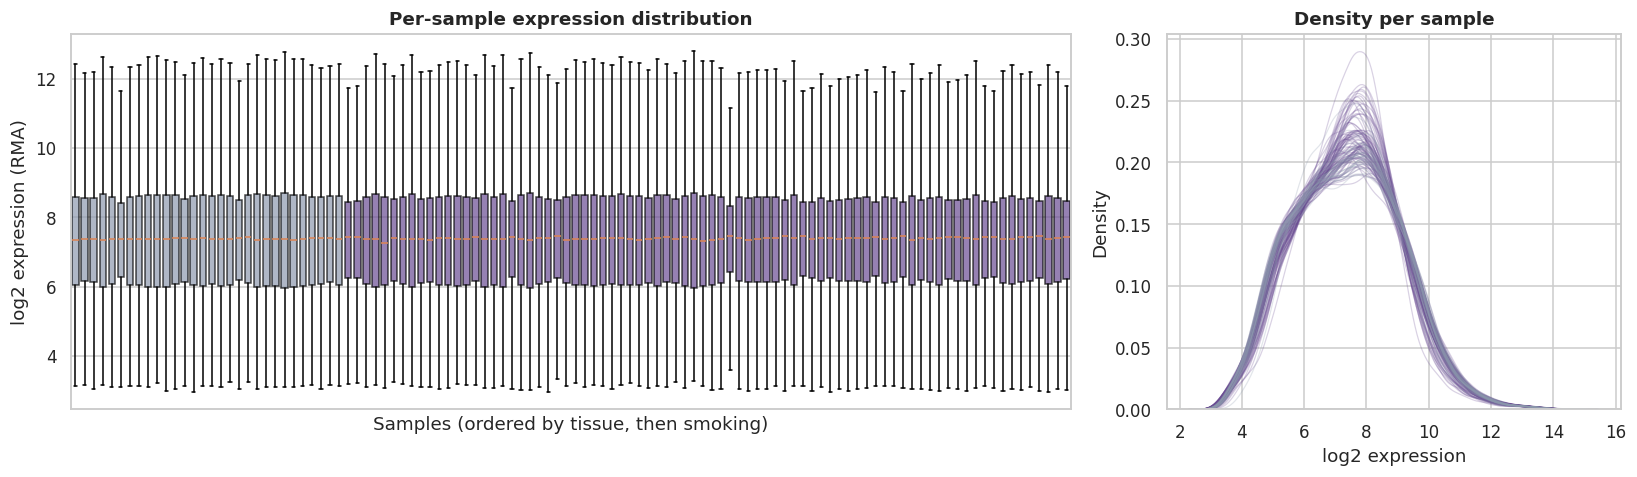

Sample medians: 7.27 - 7.46 (SD = 0.032)


In [8]:
order = pheno.sort_values(["tissue", "smoking"]).index
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

bp = ax[0].boxplot([expr_gene[s].values for s in order], widths=0.7, showfliers=False, patch_artist=True)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(PALETTE.get(pheno.loc[s, "tissue"], "grey")); patch.set_alpha(0.7)
ax[0].set_xticks([]); ax[0].set_xlabel("Samples (ordered by tissue, then smoking)"); ax[0].set_ylabel("log2 expression (RMA)")
ax[0].set_title("Per-sample expression distribution")

for tissue in ["Tumor", "Normal"]:
    for s in pheno.index[pheno.tissue == tissue]:
        sns.kdeplot(expr_gene[s], ax=ax[1], color=PALETTE[tissue], alpha=0.25, linewidth=0.8)
ax[1].set_title("Density per sample"); ax[1].set_xlabel("log2 expression")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/qc_sample_distributions.png"); plt.show()

med = expr_gene.median()
print(f"Sample medians: {med.min():.2f} - {med.max():.2f} (SD = {med.std():.3f})")

**(b) Sample-to-sample correlation.** Each sample's mean correlation with all others is converted to a z-score; samples with z < -3 are flagged as potential outliers. Flagged samples are **reported, not automatically removed**

Samples flagged as potential outliers (z < -3): ['GSM1062769', 'GSM1062783', 'GSM1062837']


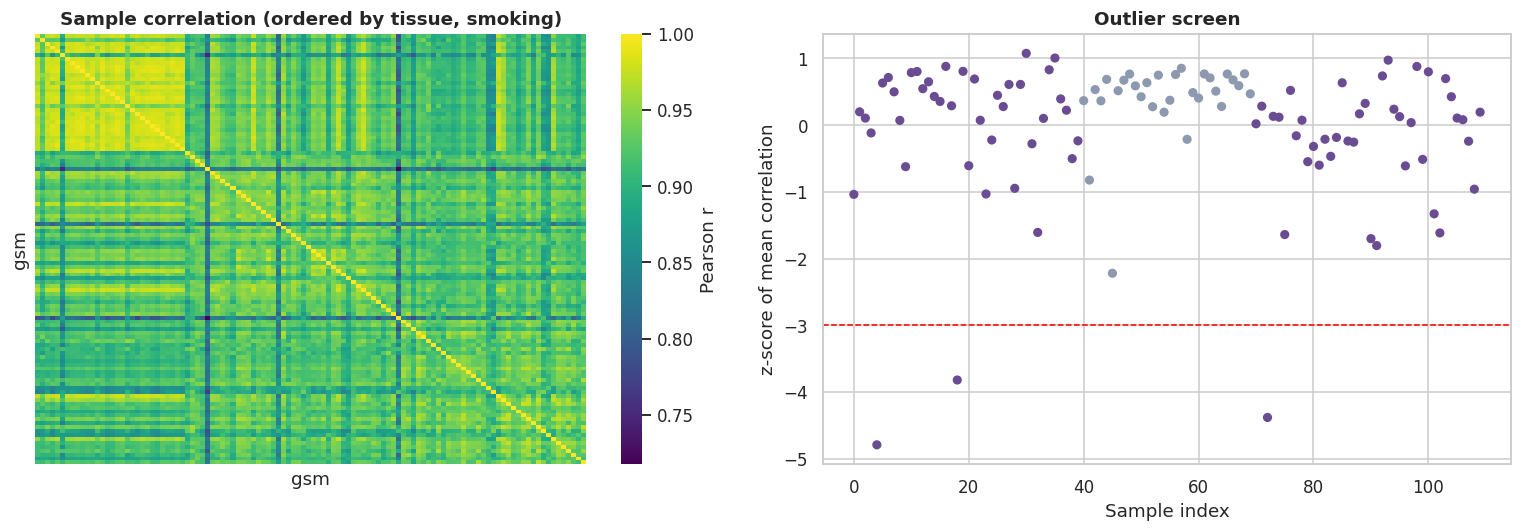

In [9]:
corr = expr_gene.corr(method="pearson")
mean_corr = (corr.sum() - 1) / (corr.shape[0] - 1)
z_corr = (mean_corr - mean_corr.mean()) / mean_corr.std()
flagged = z_corr[z_corr < -3].index.tolist()
print("Samples flagged as potential outliers (z < -3):", flagged if flagged else "none")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cg = corr.loc[order, order]
sns.heatmap(cg, cmap="viridis", ax=ax[0], xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson r"})
ax[0].set_title("Sample correlation (ordered by tissue, smoking)")
colors = pheno.loc[z_corr.index, "tissue"].map(PALETTE)
ax[1].scatter(range(len(z_corr)), z_corr.values, c=colors, s=25)
ax[1].axhline(-3, color="red", ls="--", lw=1); ax[1].set_xlabel("Sample index"); ax[1].set_ylabel("z-score of mean correlation")
ax[1].set_title("Outlier screen")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/qc_sample_correlation.png"); plt.show()

**(c) Does the data agree with biology we know must hold?**

1. *Housekeeping and lung-lineage genes should be highly expressed; genes from unrelated organs should be low.* We show each gene's percentile rank of mean expression across the array.
2. *Sex genes:* `XIST` must be high only in females and Y-chromosome genes (`RPS4Y1`, `DDX3Y`, `KDM5D`, `EIF1AY`, `UTY`, `ZFY`) only in males. This verifies that sample identities and metadata are not scrambled, and lets us infer sex if it is missing.
3. *Tumour vs normal:* well-established directions in lung adenocarcinoma (proliferation genes such as `TOP2A`, `MKI67`, `CDK1` up; alveolar/endothelial genes such as `AGER`, `CAV1` down; `ETS2`, reported as down-regulated in this very study).

In [10]:
# (c1) housekeeping, lung lineage, off-tissue genes
gene_mean = expr_gene.mean(axis=1)
pct = gene_mean.rank(pct=True) * 100
groups = {
    "Housekeeping (expect high)": ["ACTB", "GAPDH", "B2M", "RPLP0", "PPIA"],
    "Lung lineage (expect high)": ["SFTPB", "SFTPC", "NAPSA", "NKX2-1", "SFTPA1"],
    "Off-tissue (expect low)": ["ALB", "INS", "GCG", "MYH6", "TTR"],
}
rows = []
for grp, gl in groups.items():
    for g in gl:
        if g in pct.index:
            rows.append({"group": grp, "gene": g, "mean_log2": round(gene_mean[g], 2), "percentile": round(pct[g], 1)})
bio1 = pd.DataFrame(rows)
display(bio1)
for grp, sub in bio1.groupby("group"):
    print(f"{grp:30s} median percentile = {sub['percentile'].median():.0f}")

# (c2) sex genes
fem, male = ["XIST"], ["RPS4Y1", "DDX3Y", "KDM5D", "EIF1AY", "UTY", "ZFY"]
fem = [g for g in fem if g in expr_gene.index]
male = [g for g in male if g in expr_gene.index]
print("\nSex genes found on the array:", fem + male)
if fem and male:
    xist = expr_gene.loc[fem].mean()
    ygenes = expr_gene.loc[male].mean()
    sex_score = xist - ygenes                          # > 0 -> female-like
    pheno["sex_inferred"] = np.where(sex_score > 0, "Female", "Male")
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    hue = pheno["sex_meta"] if "sex_meta" in pheno else pheno["sex_inferred"]
    sns.scatterplot(x=ygenes, y=xist, hue=hue, ax=ax, s=45)
    ax.set_xlabel("Mean Y-chromosome gene expression (log2)"); ax.set_ylabel("XIST expression (log2)")
    ax.set_title("Sex-gene check"); plt.tight_layout(); plt.savefig(f"{OUTDIR}/qc_sex_genes.png"); plt.show()
    if "sex_meta" in pheno:
        cmp = pd.crosstab(pheno["sex_meta"], pheno["sex_inferred"])
        display(cmp)
        agree = (pheno["sex_meta"] == pheno["sex_inferred"])[pheno["sex_meta"].notna()].mean()
        print(f"Agreement between metadata sex and expression-inferred sex: {agree*100:.1f}%")
        mism = pheno.index[(pheno["sex_meta"].notna()) & (pheno["sex_meta"] != pheno["sex_inferred"])].tolist()
        print("Samples with discordant sex (possible sample swap):", mism if mism else "none")

# final sex variable: metadata if available, otherwise inferred from expression
if "sex_meta" in pheno and pheno["sex_meta"].notna().mean() > 0.9:
    pheno["sex_final"] = pheno["sex_meta"].fillna(pheno.get("sex_inferred"))
elif "sex_inferred" in pheno:
    pheno["sex_final"] = pheno["sex_inferred"]
print("\nSex variable used downstream:", "sex_final" in pheno, "|", pheno["sex_final"].value_counts().to_dict() if "sex_final" in pheno else "")

# (c3) known tumour vs normal directions
expected = {"TOP2A": "up", "MKI67": "up", "CDK1": "up", "AGER": "down", "CAV1": "down", "ETS2": "down"}
tum_ids = pheno.index[pheno.tissue == "Tumor"]; nor_ids = pheno.index[pheno.tissue == "Normal"]
rows = []
for g, d in expected.items():
    if g in expr_gene.index and len(nor_ids) > 1:
        a, b = expr_gene.loc[g, tum_ids], expr_gene.loc[g, nor_ids]
        lfc = a.mean() - b.mean(); p = stats.ttest_ind(a, b, equal_var=False)[1]
        rows.append({"gene": g, "expected (tumour vs normal)": d, "observed log2FC": round(lfc, 2),
                     "Welch p": f"{p:.1e}", "consistent": (lfc > 0) == (d == "up")})
bio3 = pd.DataFrame(rows)
display(bio3)
if len(bio3):
    print(f"{bio3['consistent'].sum()} of {len(bio3)} marker genes move in the expected direction.")

,group,gene,mean_log2,percentile
0,Housekeeping (expect high),ACTB,12.96,99.9
1,Housekeeping (expect high),GAPDH,12.85,99.8
2,Housekeeping (expect high),B2M,12.32,99.7
3,Housekeeping (expect high),RPLP0,13.03,99.9
4,Housekeeping (expect high),PPIA,11.27,98.9
5,Lung lineage (expect high),SFTPB,12.06,99.5
6,Lung lineage (expect high),SFTPC,10.92,98.3
7,Lung lineage (expect high),NAPSA,11.39,99.1
8,Lung lineage (expect high),NKX2-1,8.34,70.9
9,Lung lineage (expect high),SFTPA1,11.46,99.2


Housekeeping (expect high)     median percentile = 100
Lung lineage (expect high)     median percentile = 99
Off-tissue (expect low)        median percentile = 25

Sex genes found on the array: ['RPS4Y1', 'DDX3Y', 'KDM5D', 'EIF1AY', 'UTY', 'ZFY']

Sex variable used downstream: False | 


,gene,expected (tumour vs normal),observed log2FC,Welch p,consistent
0,TOP2A,up,1.90,2.6e-23,True
1,MKI67,up,1.35,1.7e-18,True
2,CDK1,up,1.02,3.5e-11,True
3,AGER,down,-3.41,8.8e-24,True
4,CAV1,down,-2.31,6.7e-32,True
5,ETS2,down,-1.00,1.0e-18,True


6 of 6 marker genes move in the expected direction.


### 3.5 Filter low-expression genes
In log2 RMA data, genes whose expression is at the background level in essentially all samples carry no usable signal, and testing them only increases the multiple-testing burden. We remove the genes whose **mean** expression (across all samples, ignoring group labels, so the filter cannot bias the smoker-vs-never test) falls in the lowest `LOW_EXPR_QUANTILE`. Values of the retained genes are unchanged.

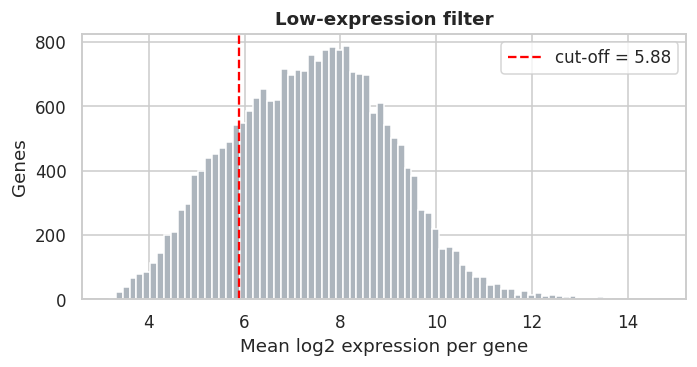

Genes before filter: 23307 | after: 18645
Tumour samples used for the smoker-vs-never comparison: {'Never': 40, 'Smoker': 40}


In [11]:
cutoff = gene_mean.quantile(LOW_EXPR_QUANTILE)
keep = gene_mean >= cutoff
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(gene_mean, bins=80, color="#adb5bd")
ax.axvline(cutoff, color="red", ls="--", label=f"cut-off = {cutoff:.2f}")
ax.set_xlabel("Mean log2 expression per gene"); ax.set_ylabel("Genes"); ax.legend()
ax.set_title("Low-expression filter"); plt.tight_layout(); plt.savefig(f"{OUTDIR}/qc_low_expression_filter.png"); plt.show()

expr = expr_gene.loc[keep]
print(f"Genes before filter: {expr_gene.shape[0]} | after: {expr.shape[0]}")

# convenient subsets
tumor_ids = pheno.index[(pheno.tissue == "Tumor") & pheno.smoking.isin(["Smoker", "Never"])]
expr_t = expr[tumor_ids]
pheno_t = pheno.loc[tumor_ids].copy()
print("Tumour samples used for the smoker-vs-never comparison:", pheno_t["smoking"].value_counts().to_dict())
expr.to_csv(f"{OUTDIR}/expression_gene_level_filtered.csv.gz")

## 4. Exploratory data analysis

Before any test, we ask: (i) are smokers and never-smokers comparable on other variables (sex, age, stage)? If not, those variables are **confounders** and must be handled. (ii) What are the dominant sources of variation in the data? (iii) Is there any visible grouping by smoking status or any outlier?

### 4.1 Cohort characteristics and potential confounders (tumours only)

In [12]:
def compare_groups(df, var, group="smoking"):
    sub = df[[var, group]].dropna()
    if sub.empty or sub[group].nunique() < 2 or sub[var].nunique() < 2:
        return None
    if pd.api.types.is_numeric_dtype(sub[var]):
        a = sub.loc[sub[group] == "Smoker", var]; b = sub.loc[sub[group] == "Never", var]
        p = stats.mannwhitneyu(a, b)[1]
        desc = f"Smoker median {a.median():.1f} (n={len(a)}) vs Never median {b.median():.1f} (n={len(b)})"
        test = "Mann-Whitney U"
    else:
        ctab = pd.crosstab(sub[var], sub[group])
        if ctab.shape == (2, 2):
            p, test = stats.fisher_exact(ctab)[1], "Fisher exact"
        else:
            p, test = stats.chi2_contingency(ctab)[1], "Chi-square"
        desc = "; ".join(f"{idx}: {row.get('Smoker', 0)} S / {row.get('Never', 0)} N" for idx, row in ctab.iterrows())
    return {"variable": var, "test": test, "p-value": p, "summary": desc}

# every low-cardinality metadata column is a candidate covariate (except labels already used)
skip = {"title", "source_name", smoke_cols[0] if smoke_cols else None, sex_col, age_col, stage_col}
extra = [c for c in meta.columns if c not in skip and 2 <= meta.loc[tumor_ids, c].nunique() <= 8]
for c in extra:
    pheno_t["meta_" + c] = meta.loc[tumor_ids, c].values

cand_vars = [v for v in ["sex_final", "age", "stage"] if v in pheno_t.columns] + [c for c in pheno_t.columns if c.startswith("meta_")]
res_conf = [compare_groups(pheno_t, v) for v in cand_vars]
conf_table = pd.DataFrame([r for r in res_conf if r])
if len(conf_table):
    display(conf_table.style.format({"p-value": "{:.3g}"}))
    print("Variables with p < 0.10 are imbalanced between smokers and never-smokers and should be treated as potential confounders.")
else:
    print("No additional covariates available to compare.")

# decide which covariates to adjust for in the DE model (complete, informative, and not too sparse)
ADJUST_FOR = []
for v in ["sex_final", "age"]:
    if v in pheno_t.columns and pheno_t[v].isna().mean() <= 0.10 and pheno_t[v].nunique() > 1:
        ADJUST_FOR.append(v)
# To adjust for other covariates as well, edit the list manually, e.g. ADJUST_FOR = ["sex_final", "age", "meta_race"]
print("\nCovariates used for the adjusted model:", ADJUST_FOR if ADJUST_FOR else "none available (unadjusted analysis only)")

No additional covariates available to compare.

Covariates used for the adjusted model: none available (unadjusted analysis only)


### 4.2 Global structure: PCA
We run PCA on the 2,000 most variable genes (mean-centred; the data are already on a common log2 scale) and colour the samples by tissue, smoking status and sex. We also test each of the leading PCs for association with each variable. PCs strongly associated with a *technical* or *confounding* variable would warn us about batch/confounding effects.

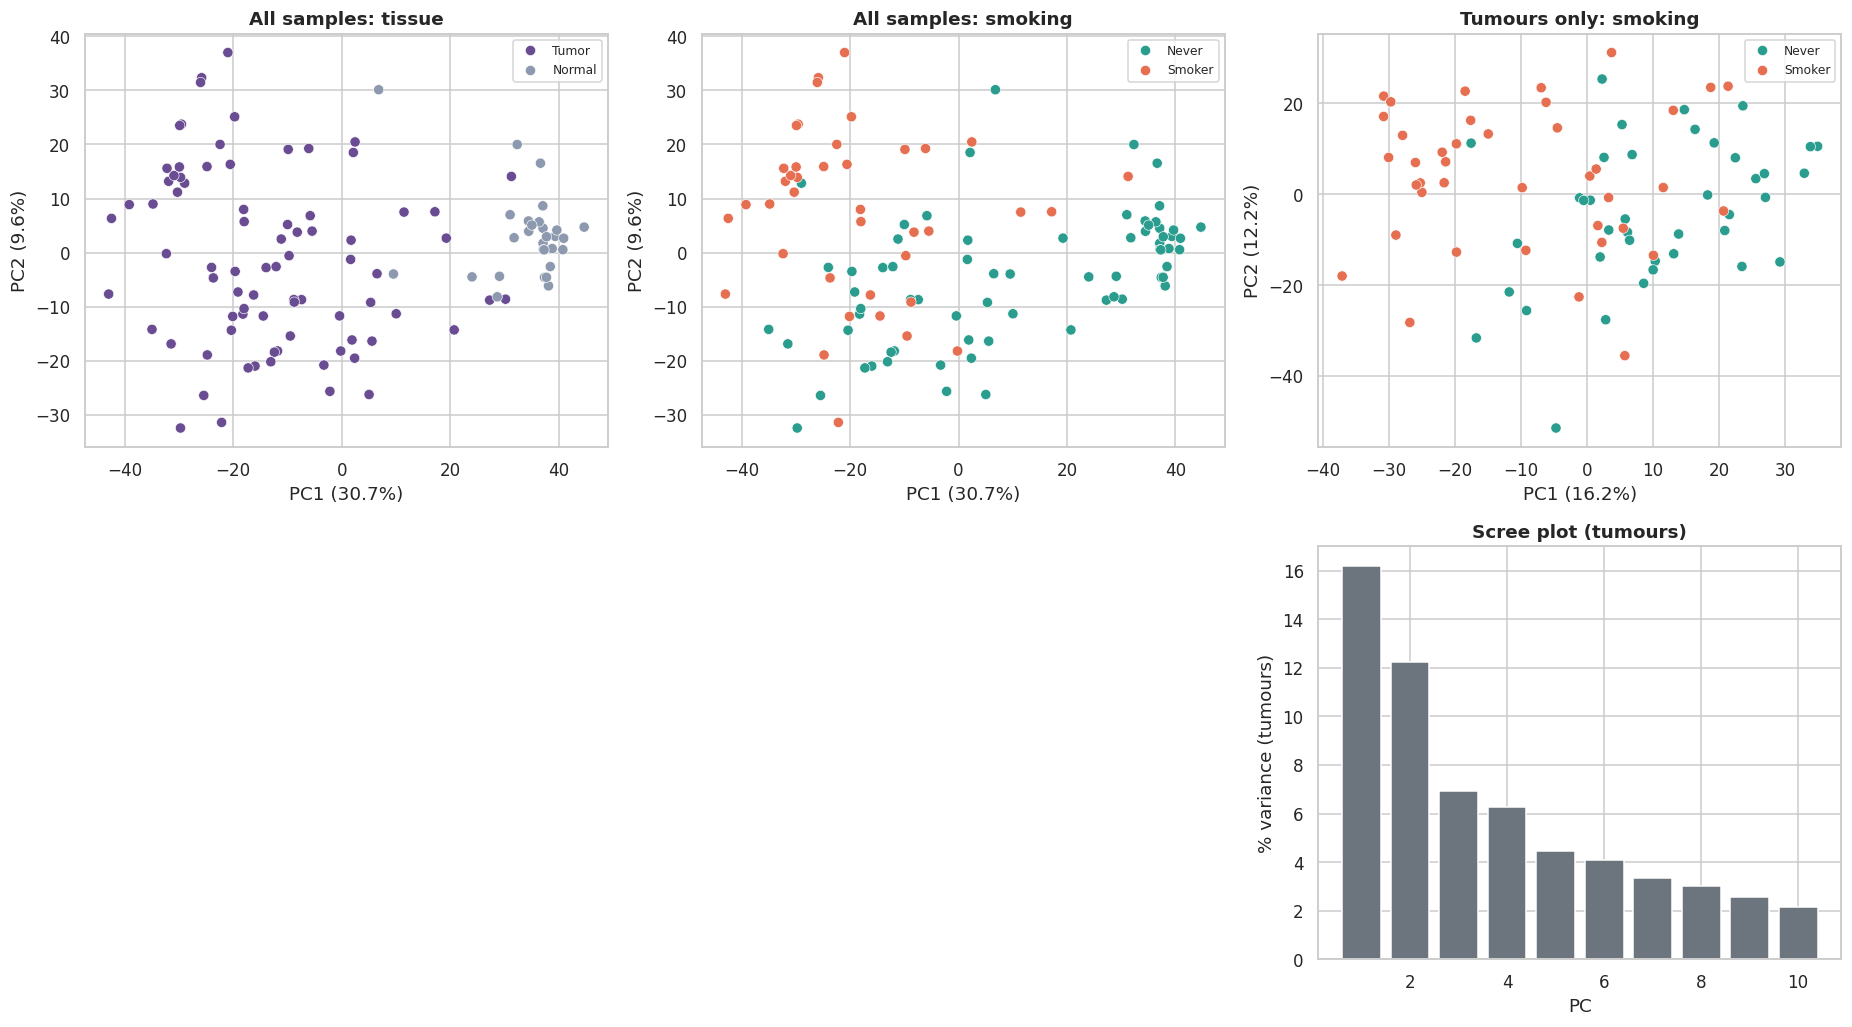

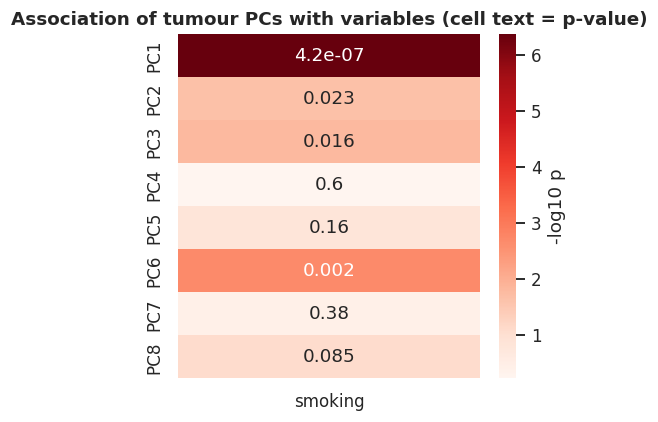

Tumour samples > 3 SD from the PC1/PC2 centroid: none


In [13]:
from sklearn.decomposition import PCA

def pca_scores(mat, n_top=2000, n_comp=10):
    top = mat.var(axis=1).sort_values(ascending=False).index[:n_top]
    Xc = mat.loc[top].T
    Xc = Xc - Xc.mean()
    pca = PCA(n_components=n_comp, random_state=SEED).fit(Xc)
    sc = pd.DataFrame(pca.transform(Xc), index=Xc.index, columns=[f"PC{i+1}" for i in range(n_comp)])
    return sc, pca.explained_variance_ratio_

sc_all, ev_all = pca_scores(expr)
sc_t, ev_t = pca_scores(expr_t)

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
def scatter(ax, sc, ev, labels, title, pal=None):
    sns.scatterplot(x=sc["PC1"], y=sc["PC2"], hue=labels.loc[sc.index], palette=pal, s=45, ax=ax, edgecolor="white", linewidth=0.4)
    ax.set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({ev[1]*100:.1f}%)"); ax.set_title(title)
    ax.legend(title="", fontsize=8, loc="best")

scatter(axes[0, 0], sc_all, ev_all, pheno["tissue"], "All samples: tissue", PALETTE)
scatter(axes[0, 1], sc_all, ev_all, pheno["smoking"].fillna("n/a"), "All samples: smoking", {**PALETTE, "n/a": "#ced4da"})
scatter(axes[0, 2], sc_t, ev_t, pheno_t["smoking"], "Tumours only: smoking", PALETTE)
if "sex_final" in pheno_t:
    scatter(axes[1, 0], sc_t, ev_t, pheno_t["sex_final"], "Tumours only: sex")
else:
    axes[1, 0].axis("off")
if "age" in pheno_t:
    sc_age = axes[1, 1].scatter(sc_t["PC1"], sc_t["PC2"], c=pheno_t["age"], cmap="viridis", s=45)
    plt.colorbar(sc_age, ax=axes[1, 1], label="age"); axes[1, 1].set_title("Tumours only: age")
    axes[1, 1].set_xlabel("PC1"); axes[1, 1].set_ylabel("PC2")
else:
    axes[1, 1].axis("off")
axes[1, 2].bar(range(1, 11), ev_t * 100, color="#6c757d"); axes[1, 2].set_xlabel("PC"); axes[1, 2].set_ylabel("% variance (tumours)")
axes[1, 2].set_title("Scree plot (tumours)")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/eda_pca.png"); plt.show()

# association of PCs with variables
def pc_pvalue(scores, s):
    s = s.dropna()
    if s.nunique() < 2:
        return np.nan
    sc = scores.loc[s.index]
    if pd.api.types.is_numeric_dtype(s):
        return stats.spearmanr(sc, s)[1]
    gs = [sc[s == g] for g in s.unique() if (s == g).sum() > 1]
    return stats.kruskal(*gs)[1] if len(gs) >= 2 else np.nan

vars_pc = ["smoking"] + [v for v in cand_vars]
pc_p = pd.DataFrame({v: [pc_pvalue(sc_t[f"PC{i}"], pheno_t[v]) for i in range(1, 9)] for v in vars_pc}, index=[f"PC{i}" for i in range(1, 9)])
plt.figure(figsize=(1.2 * len(vars_pc) + 3, 4))
pc_text = pc_p.astype(float).apply(lambda col: col.map(lambda x: f"{x:.2g}"))
sns.heatmap(-np.log10(pc_p.astype(float)), annot=pc_text, fmt="", cmap="Reds", cbar_kws={"label": "-log10 p"})
plt.title("Association of tumour PCs with variables (cell text = p-value)")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/eda_pc_associations.png"); plt.show()

# PCA-based outlier screen
d = np.sqrt(((sc_t[["PC1", "PC2"]] - sc_t[["PC1", "PC2"]].mean()) ** 2).sum(axis=1))
pca_out = d[(d - d.mean()) / d.std() > 3].index.tolist()
print("Tumour samples > 3 SD from the PC1/PC2 centroid:", pca_out if pca_out else "none")

### 4.3 Hierarchical clustering of the most variable genes (tumours)
If smoking status were the dominant source of variation, tumours would split cleanly by smoking in this heatmap. More commonly, histological, tumour-purity, sex and other effects dominate and smoking-related differences are subtle: that expectation is why we need a formal statistical test in Section 5.

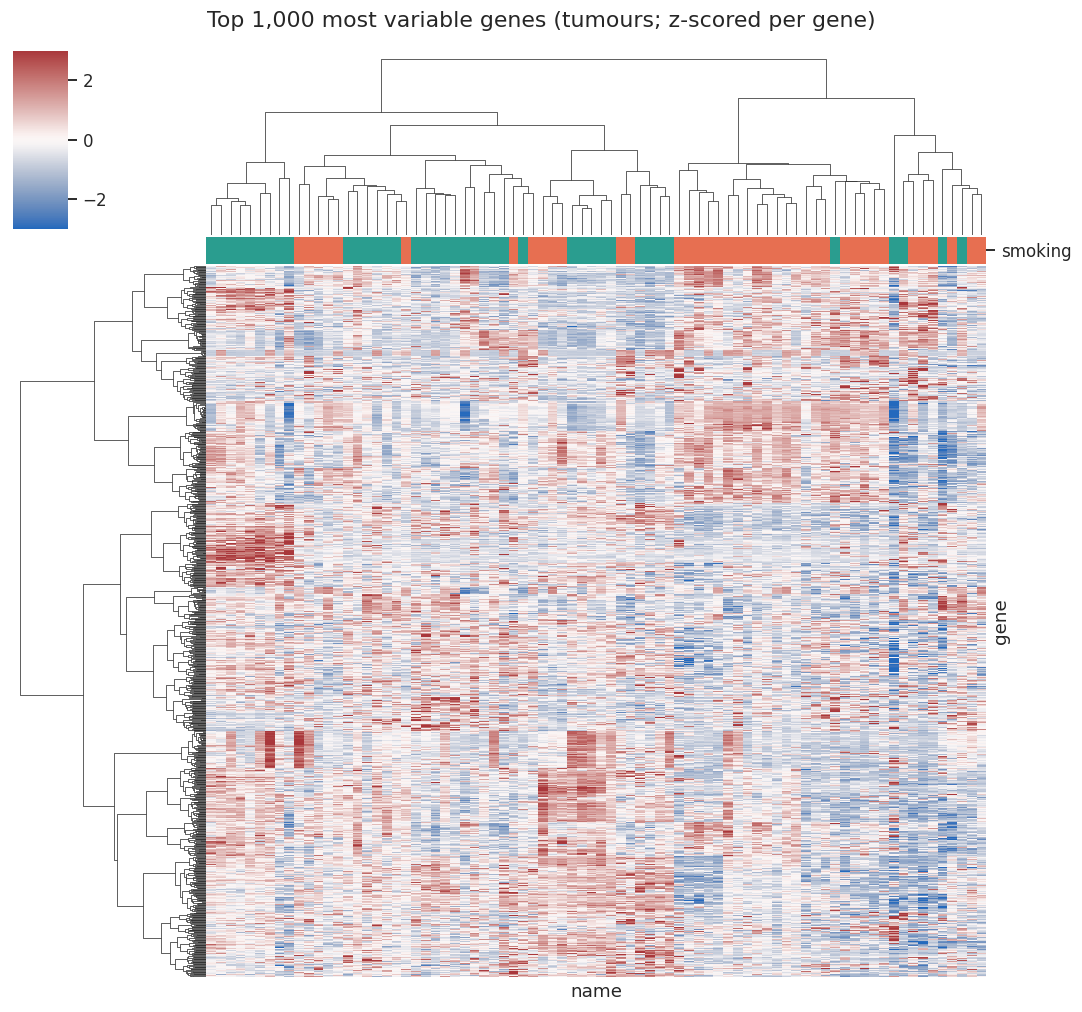

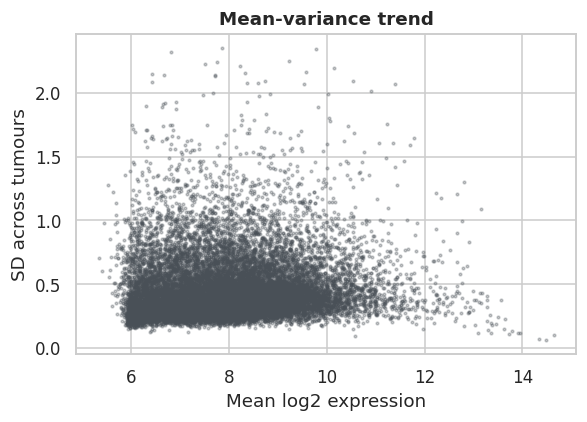

In [14]:
top_var = expr_t.var(axis=1).sort_values(ascending=False).index[:1000]
H = expr_t.loc[top_var]
Hz = H.sub(H.mean(axis=1), axis=0).div(H.std(axis=1), axis=0)

col_colors = pd.DataFrame({"smoking": pheno_t["smoking"].map(PALETTE)}, index=pheno_t.index)
if "sex_final" in pheno_t:
    col_colors["sex"] = pheno_t["sex_final"].map({"Female": "#f4a261", "Male": "#264653"})

g = sns.clustermap(Hz, cmap="vlag", center=0, vmin=-3, vmax=3, col_colors=col_colors,
                   xticklabels=False, yticklabels=False, figsize=(10, 9), method="ward", metric="euclidean")
g.fig.suptitle("Top 1,000 most variable genes (tumours; z-scored per gene)", y=1.02)
g.savefig(f"{OUTDIR}/eda_clustermap_top_variable.png"); plt.show()

# mean-variance relationship (justifies variance moderation in Section 5)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(expr_t.mean(axis=1), expr_t.std(axis=1), s=3, alpha=0.3, color="#495057")
ax.set_xlabel("Mean log2 expression"); ax.set_ylabel("SD across tumours"); ax.set_title("Mean-variance trend")
plt.tight_layout(); plt.show()

## 5. Core analysis

### 5.1 Differential expression method
For each gene we fit a linear model on the log2 expression values

`expression ~ smoking_status [+ sex + age]`

and test the smoking coefficient. Because there are only ~40 tumours per group, gene-wise variance estimates are noisy, so we use the **empirical-Bayes moderated t-statistic** of Smyth (2004), the approach behind limma, which shrinks each gene's variance towards a common trend and is the standard choice for microarray data. Python has no maintained limma port, so it is implemented below (about 40 lines) and **validated against `statsmodels` OLS** to make sure the implementation is right. p-values are adjusted with Benjamini-Hochberg (FDR).

The effect size `logFC` is the difference in mean log2 expression, **Smoker minus Never** (positive = higher in smokers). Because values are already log2, no extra transformation is needed.

In [15]:
def fit_linear_model(Y, X, coef_idx):
    """Gene-wise OLS. Y: genes x samples, X: samples x p. Returns coefficient, unscaled SD, residual variance, residual df."""
    n, p = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    B = Y @ X @ XtX_inv
    resid = Y - B @ X.T
    df = n - p
    s2 = (resid ** 2).sum(axis=1) / df
    return B[:, coef_idx], np.sqrt(XtX_inv[coef_idx, coef_idx]), s2, df

def trigamma_inverse(x):
    if x > 1e7:
        return 1 / np.sqrt(x)
    if x < 1e-6:
        return 1 / x
    y = 0.5 + 1 / x
    for _ in range(50):
        tri = special.polygamma(1, y)
        dif = tri * (1 - tri / x) / special.polygamma(2, y)
        y = y + dif
        if -dif / y < 1e-8:
            break
    return y

def fit_f_dist(s2, df):
    """Estimate the prior variance s0^2 and prior degrees of freedom d0 (limma's fitFDist, common df)."""
    s2 = np.maximum(s2, 1e-12)
    z = np.log(s2)
    e = z - special.digamma(df / 2) + np.log(df / 2)
    emean, evar = e.mean(), e.var(ddof=1) - special.polygamma(1, df / 2)
    if evar > 0:
        d0 = 2 * trigamma_inverse(evar)
        s02 = np.exp(emean + special.digamma(d0 / 2) - np.log(d0 / 2))
    else:
        d0, s02 = np.inf, np.exp(emean)
    return s02, d0

def build_design(df, group_col, positive, covariates):
    X = pd.DataFrame(index=df.index)
    X["Intercept"] = 1.0
    X["group"] = (df[group_col] == positive).astype(float)
    for c in covariates:
        if pd.api.types.is_numeric_dtype(df[c]):
            X[c] = df[c].astype(float) - df[c].astype(float).mean()
        else:
            X = X.join(pd.get_dummies(df[c], prefix=c, drop_first=True).astype(float))
    return X

def run_de(expr_df, pheno_df, group_col, positive, covariates=(), moderate=True):
    cols = [group_col] + list(covariates)
    ph = pheno_df[cols].dropna()
    Y = expr_df[ph.index].values.astype(float)
    X = build_design(ph, group_col, positive, covariates)
    beta, sdu, s2, df = fit_linear_model(Y, X.values, X.columns.get_loc("group"))
    if moderate:
        s02, d0 = fit_f_dist(s2, df)
        s2_post = (d0 * s02 + df * s2) / (d0 + df) if np.isfinite(d0) else np.full_like(s2, s02)
        df_tot = df + d0
    else:
        s02, d0, s2_post, df_tot = np.nan, 0.0, s2, df
    t = beta / (np.sqrt(s2_post) * sdu)
    p = 2 * (stats.norm.sf(np.abs(t)) if np.isinf(df_tot) else stats.t.sf(np.abs(t), df_tot))
    res = pd.DataFrame({"logFC": beta, "AveExpr": Y.mean(axis=1), "t": t, "SE": np.sqrt(s2_post) * sdu, "P": p}, index=expr_df.index)
    res["FDR"] = multipletests(res["P"], method="fdr_bh")[1]
    info = {"n": len(ph), "n_group": int(X["group"].sum()), "design_columns": list(X.columns), "prior_df": d0, "prior_var": s02}
    return res.sort_values("P"), info

# validation of the implementation against statsmodels
import statsmodels.api as sm
chk_ph = pheno_t[["smoking"] + ADJUST_FOR].dropna()
chk_res, _ = run_de(expr_t, pheno_t, "smoking", "Smoker", ADJUST_FOR, moderate=False)
Xchk = sm.add_constant(build_design(chk_ph, "smoking", "Smoker", ADJUST_FOR).drop(columns="Intercept"))
max_diff = 0
for g in chk_res.index[:5]:
    ols = sm.OLS(expr_t.loc[g, chk_ph.index].values.astype(float), Xchk.values).fit()
    max_diff = max(max_diff, abs(ols.params[1] - chk_res.loc[g, "logFC"]), abs(ols.tvalues[1] - chk_res.loc[g, "t"]))
print(f"Max |difference| vs statsmodels OLS (logFC and t, 5 genes): {max_diff:.2e}")
assert max_diff < 1e-6

Max |difference| vs statsmodels OLS (logFC and t, 5 genes): 2.22e-13


### 5.2 Positive control: tumour vs normal
Before trusting the pipeline on the (subtle) smoking contrast, we check that it recovers the large, well-known tumour-vs-normal differences. This is a *pipeline* check, not part of the research question. Normal samples were collected from a subset of the never-smoker patients, so this contrast is unadjusted and unpaired.

Tumour vs normal: 11543 genes at FDR < 0.05 out of 18645 (6983 up, 4560 down in tumour)
Prior df (d0) from variance moderation: 3.8


,logFC,AveExpr,t,SE,P,FDR
gene,,,,,,
TOP2A,1.9010,7.9710,9.3014,0.2044,0.0,0.0
MKI67,1.3457,7.6650,8.3989,0.1602,0.0,0.0
CDK1,1.0186,6.4434,5.3507,0.1904,0.0,0.0
AGER,-3.4141,9.5555,-13.3534,0.2557,0.0,0.0
CAV1,-2.3122,10.2202,-11.4938,0.2012,0.0,0.0
ETS2,-1.0001,10.5954,-8.0463,0.1243,0.0,0.0


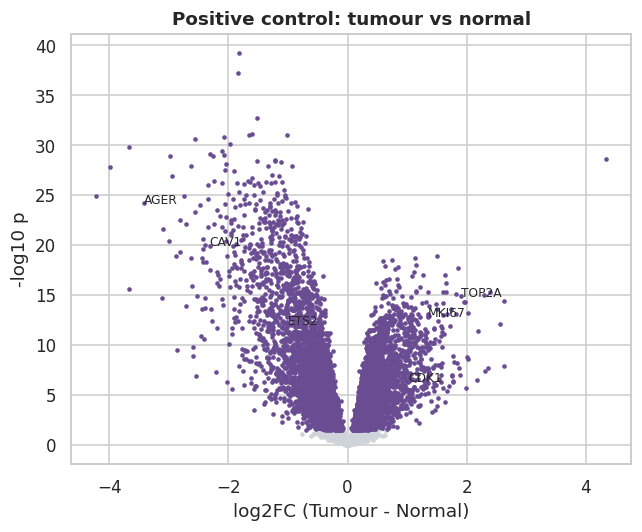

In [16]:
res_tn, info_tn = run_de(expr, pheno[pheno.tissue.isin(["Tumor", "Normal"])], "tissue", "Tumor")
n_sig_tn = (res_tn.FDR < FDR_THRESHOLD).sum()
print(f"Tumour vs normal: {n_sig_tn} genes at FDR < {FDR_THRESHOLD} out of {len(res_tn)} "
      f"({(res_tn[res_tn.FDR < FDR_THRESHOLD].logFC > 0).sum()} up, {(res_tn[res_tn.FDR < FDR_THRESHOLD].logFC < 0).sum()} down in tumour)")
print("Prior df (d0) from variance moderation:", round(info_tn["prior_df"], 1))
chk = res_tn.reindex(["TOP2A", "MKI67", "CDK1", "AGER", "CAV1", "ETS2"]).dropna()
display(chk.round(4))
res_tn.to_csv(f"{OUTDIR}/DE_tumor_vs_normal.csv")

fig, ax = plt.subplots(figsize=(6, 5))
sig = res_tn.FDR < FDR_THRESHOLD
ax.scatter(res_tn.logFC[~sig], -np.log10(res_tn.P[~sig]), s=4, c="#ced4da")
ax.scatter(res_tn.logFC[sig], -np.log10(res_tn.P[sig]), s=4, c=PALETTE["Tumor"])
for g in chk.index:
    ax.annotate(g, (chk.loc[g, "logFC"], -np.log10(chk.loc[g, "P"])), fontsize=8)
ax.set_xlabel("log2FC (Tumour - Normal)"); ax.set_ylabel("-log10 p"); ax.set_title("Positive control: tumour vs normal")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/de_positive_control_volcano.png"); plt.show()

### 5.3 Primary analysis: smokers vs never-smokers (tumours only)
We fit two models:
- **Model A (unadjusted):** `expression ~ smoking`
- **Model B (adjusted):** `expression ~ smoking + covariates` (sex and age when available). If the groups differ in sex or age, Model B is the one that answers the question *"is the difference due to smoking rather than to sex/age?"*

The primary result is Model B when covariates are available, otherwise Model A. A Welch t-test (no variance moderation, no covariates) is added as a sensitivity check.

In [17]:
resA, infoA = run_de(expr_t, pheno_t, "smoking", "Smoker", covariates=[])
if ADJUST_FOR:
    resB, infoB = run_de(expr_t, pheno_t, "smoking", "Smoker", covariates=ADJUST_FOR)
else:
    resB, infoB = resA, infoA
PRIMARY_LABEL = "Model B (adjusted for " + ", ".join(ADJUST_FOR) + ")" if ADJUST_FOR else "Model A (unadjusted)"
res_primary = resB.copy()

# Welch t-test sensitivity check
a = expr_t.loc[:, pheno_t.smoking == "Smoker"].values; b = expr_t.loc[:, pheno_t.smoking == "Never"].values
w_t, w_p = stats.ttest_ind(a, b, axis=1, equal_var=False)
welch = pd.DataFrame({"logFC": a.mean(axis=1) - b.mean(axis=1), "P": w_p}, index=expr_t.index)
welch["FDR"] = multipletests(welch["P"], method="fdr_bh")[1]

def n_sig(r, fdr=FDR_THRESHOLD, lfc=0):
    s = r[(r.FDR < fdr) & (r.logFC.abs() >= lfc)]
    return len(s), int((s.logFC > 0).sum()), int((s.logFC < 0).sum())

summary_rows = []
for name, r in [("Model A: unadjusted (moderated t)", resA), ("Model B: adjusted (moderated t)", resB), ("Welch t-test (unadjusted)", welch)]:
    for fdr in (0.05, 0.10):
        tot, up, dn = n_sig(r, fdr)
        summary_rows.append({"analysis": name, "FDR cut-off": fdr, "significant genes": tot, "up in smokers": up, "down in smokers": dn,
                             f"... with |log2FC| >= {LOGFC_CUTOFF}": n_sig(r, fdr, LOGFC_CUTOFF)[0]})
display(pd.DataFrame(summary_rows))
print("PRIMARY RESULT:", PRIMARY_LABEL)
print(f"Prior df d0 = {infoB['prior_df']:.1f} | n tumours = {infoB['n']} ({infoB['n_group']} smokers)")

res_primary.to_csv(f"{OUTDIR}/DE_smoker_vs_never_primary.csv")
resA.to_csv(f"{OUTDIR}/DE_smoker_vs_never_unadjusted.csv")
sig_primary = res_primary[res_primary.FDR < FDR_THRESHOLD]
print(f"\nSignificant genes in the primary analysis (FDR < {FDR_THRESHOLD}): {len(sig_primary)}")
display(res_primary.head(25).round(4))

,analysis,FDR cut-off,significant genes,up in smokers,down in smokers,... with |log2FC| >= 0.3
0,Model A: unadjusted (moderated t),0.05,8332,4835,3497,4333
1,Model A: unadjusted (moderated t),0.10,9683,5377,4306,4596
2,Model B: adjusted (moderated t),0.05,8332,4835,3497,4333
3,Model B: adjusted (moderated t),0.10,9683,5377,4306,4596
4,Welch t-test (unadjusted),0.05,8275,4825,3450,4296
5,Welch t-test (unadjusted),0.10,9637,5362,4275,4570


PRIMARY RESULT: Model A (unadjusted)
Prior df d0 = 3.4 | n tumours = 80 (40 smokers)

Significant genes in the primary analysis (FDR < 0.05): 8332


,logFC,AveExpr,t,SE,P,FDR
gene,,,,,,
MCCD1,0.5420,7.1058,11.8915,0.0456,0.0,0.0
RN7SL583P,0.5886,6.8674,11.4599,0.0514,0.0,0.0
OR13J1,0.5004,6.4846,11.3985,0.0439,0.0,0.0
RN7SL771P,0.7885,7.8705,11.3418,0.0695,0.0,0.0
LOC391003,0.4322,6.3084,11.2087,0.0386,0.0,0.0
IGLJCOR18,0.5503,7.2016,11.1367,0.0494,0.0,0.0
OPN1MW,0.4510,6.3730,11.1054,0.0406,0.0,0.0
NEU2,0.5837,6.9026,11.0940,0.0526,0.0,0.0
RN7SL63P,0.7312,6.8567,10.9743,0.0666,0.0,0.0


### 5.4 Is the result trustworthy? Calibration checks
1. **p-value histogram**: under H0 for most genes the histogram is flat; an excess near 0 indicates real signal; a U-shape or odd bumps indicate problems.
2. **Label permutation**: shuffle smoking labels among tumours (keeping the same model) many times and count how many genes reach FDR < 0.05. If the observed number is far above the permutation distribution, the result is unlikely to be a statistical artefact.
3. **Sex-chromosome genes among the hits**: if `XIST`, `RPS4Y1`, `KDM5D`... appear in the hit list, the groups are probably imbalanced by sex and the model is picking this up.
4. **Concordance between Model A, Model B and Welch**: robust hits should appear in all of them.

Observed genes with p < 0.01: 7295 | under permuted labels: mean 150.9, 95th percentile 438
Observed genes with FDR < 0.05: 8332 | under permuted labels: mean 0.08, max 14
Empirical permutation p-value (global test, count of p<0.01): 0.0050


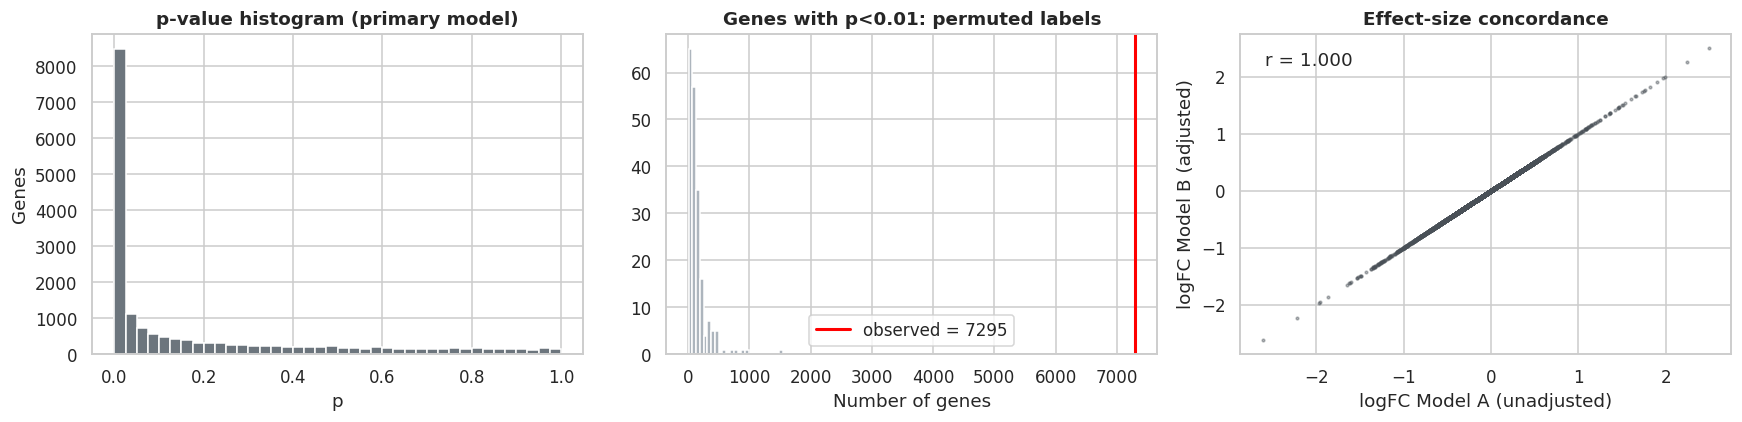


Sex-chromosome genes among significant hits: none
Genes significant in Model A, Model B and Welch at FDR < 0.05: 8245


In [18]:
rng = np.random.default_rng(SEED)
obs_fdr = (res_primary.FDR < FDR_THRESHOLD).sum()
obs_p01 = (res_primary.P < 0.01).sum()
perm_fdr, perm_p01 = [], []
for i in range(N_PERMUTATIONS):
    ph = pheno_t.copy()
    ph["smoking"] = rng.permutation(ph["smoking"].values)
    r, _ = run_de(expr_t, ph, "smoking", "Smoker", covariates=ADJUST_FOR)
    perm_fdr.append((r.FDR < FDR_THRESHOLD).sum()); perm_p01.append((r.P < 0.01).sum())
perm_fdr, perm_p01 = np.array(perm_fdr), np.array(perm_p01)
emp_p = (1 + (perm_p01 >= obs_p01).sum()) / (1 + N_PERMUTATIONS)
print(f"Observed genes with p < 0.01: {obs_p01} | under permuted labels: mean {perm_p01.mean():.1f}, 95th percentile {np.percentile(perm_p01, 95):.0f}")
print(f"Observed genes with FDR < {FDR_THRESHOLD}: {obs_fdr} | under permuted labels: mean {perm_fdr.mean():.2f}, max {perm_fdr.max()}")
print(f"Empirical permutation p-value (global test, count of p<0.01): {emp_p:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(res_primary.P, bins=40, color="#6c757d", edgecolor="white"); ax[0].set_title("p-value histogram (primary model)"); ax[0].set_xlabel("p"); ax[0].set_ylabel("Genes")
ax[1].hist(perm_p01, bins=25, color="#adb5bd", edgecolor="white"); ax[1].axvline(obs_p01, color="red", lw=2, label=f"observed = {obs_p01}")
ax[1].set_title("Genes with p<0.01: permuted labels"); ax[1].set_xlabel("Number of genes"); ax[1].legend()
ax[2].scatter(resA.logFC.reindex(resB.index), resB.logFC, s=3, alpha=0.4, color="#495057")
ax[2].set_xlabel("logFC Model A (unadjusted)"); ax[2].set_ylabel("logFC Model B (adjusted)"); ax[2].set_title("Effect-size concordance")
r_ab = np.corrcoef(resA.logFC.reindex(resB.index), resB.logFC)[0, 1]; ax[2].text(0.05, 0.9, f"r = {r_ab:.3f}", transform=ax[2].transAxes)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/de_calibration.png"); plt.show()

sexgenes = {"XIST", "RPS4Y1", "DDX3Y", "KDM5D", "EIF1AY", "UTY", "ZFY", "USP9Y", "TXLNGY", "NLGN4Y", "TSIX"}
hits_sex = sorted(sexgenes & set(sig_primary.index))
print("\nSex-chromosome genes among significant hits:", hits_sex if hits_sex else "none")
overlap = set(resA[resA.FDR < FDR_THRESHOLD].index) & set(sig_primary.index) & set(welch[welch.FDR < FDR_THRESHOLD].index)
print(f"Genes significant in Model A, Model B and Welch at FDR < {FDR_THRESHOLD}: {len(overlap)}")

### 5.5 Visualising the differential expression result

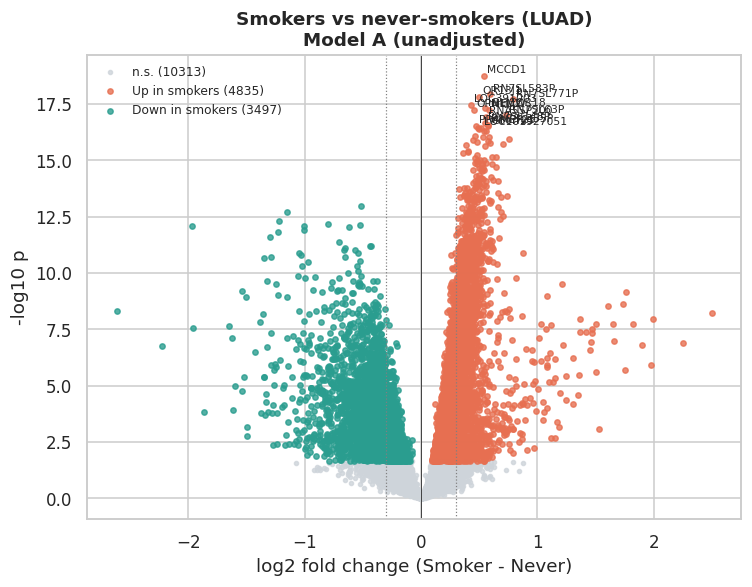

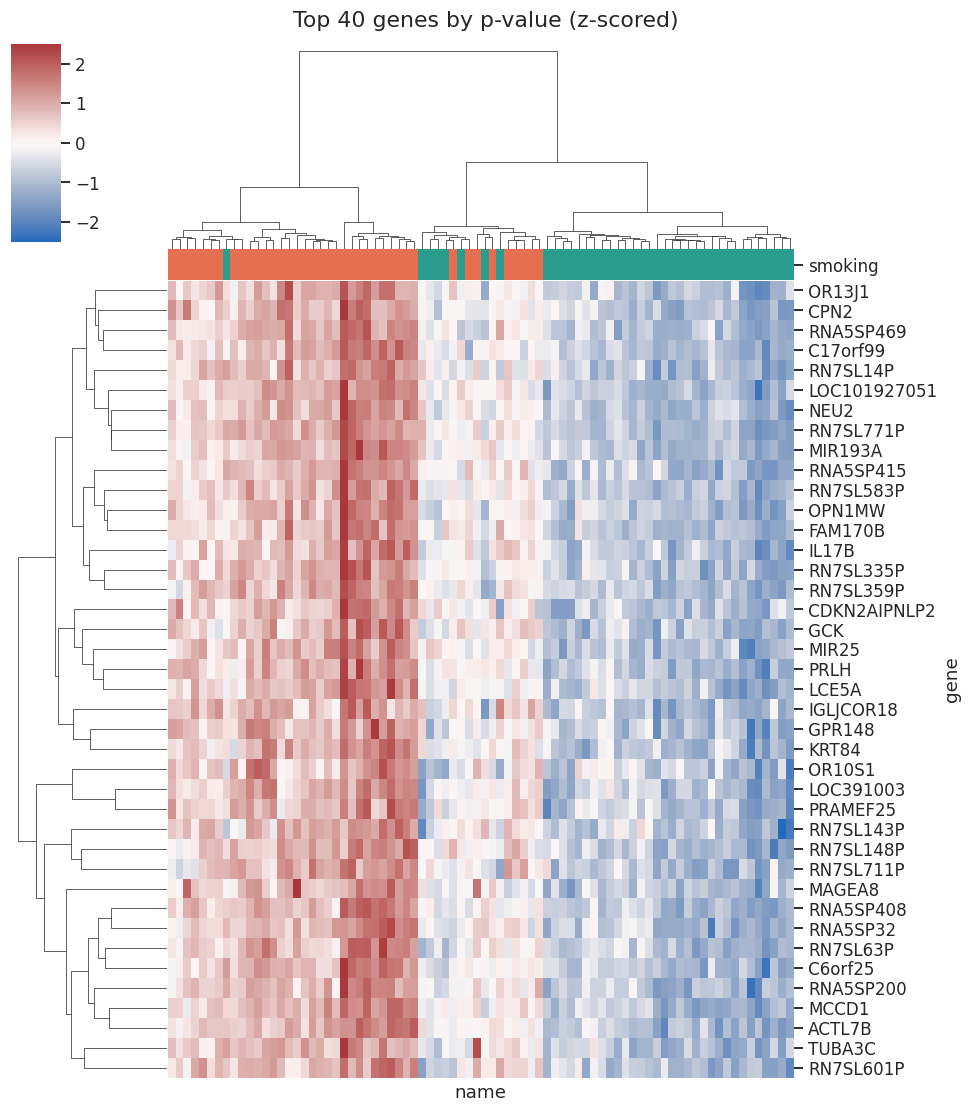

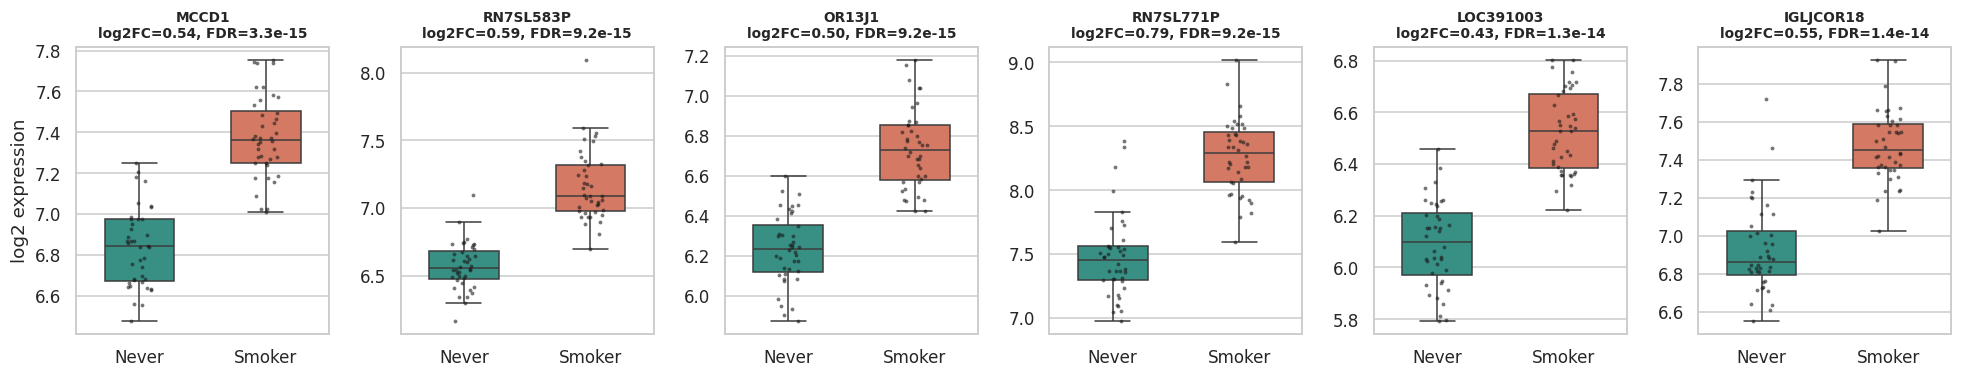

In [19]:
def volcano(res, title, fname, label_n=15):
    r = res.copy()
    r["cat"] = "n.s."
    r.loc[(r.FDR < FDR_THRESHOLD) & (r.logFC > 0), "cat"] = "Up in smokers"
    r.loc[(r.FDR < FDR_THRESHOLD) & (r.logFC < 0), "cat"] = "Down in smokers"
    colors = {"n.s.": "#ced4da", "Up in smokers": PALETTE["Smoker"], "Down in smokers": PALETTE["Never"]}
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for k, c in colors.items():
        s = r[r.cat == k]; ax.scatter(s.logFC, -np.log10(s.P), s=7 if k == "n.s." else 12, c=c, label=f"{k} ({len(s)})", alpha=0.8)
    ax.axvline(0, color="k", lw=0.5); ax.axvline(LOGFC_CUTOFF, color="grey", ls=":", lw=0.8); ax.axvline(-LOGFC_CUTOFF, color="grey", ls=":", lw=0.8)
    for g, row in r.sort_values("P").head(label_n).iterrows():
        ax.annotate(g, (row.logFC, -np.log10(row.P)), fontsize=7, xytext=(2, 2), textcoords="offset points")
    ax.set_xlabel("log2 fold change (Smoker - Never)"); ax.set_ylabel("-log10 p"); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.savefig(fname); plt.show()

volcano(res_primary, f"Smokers vs never-smokers (LUAD)\n{PRIMARY_LABEL}", f"{OUTDIR}/de_volcano_primary.png")

# heatmap of the top genes (by p-value)
top_genes = res_primary.index[:40]
Z = expr_t.loc[top_genes]; Z = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1), axis=0)
cc = pd.DataFrame({"smoking": pheno_t["smoking"].map(PALETTE)}, index=pheno_t.index)
if "sex_final" in pheno_t:
    cc["sex"] = pheno_t["sex_final"].map({"Female": "#f4a261", "Male": "#264653"})
g = sns.clustermap(Z, cmap="vlag", center=0, vmin=-2.5, vmax=2.5, col_colors=cc, xticklabels=False, figsize=(9, 10), method="ward",
                   yticklabels=True)
g.fig.suptitle("Top 40 genes by p-value (z-scored)", y=1.01); g.savefig(f"{OUTDIR}/de_heatmap_top40.png"); plt.show()

# individual genes
top6 = res_primary.index[:6]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, gname in zip(axes, top6):
    dfp = pd.DataFrame({"expr": expr_t.loc[gname], "smoking": pheno_t["smoking"]})
    sns.boxplot(data=dfp, x="smoking", y="expr", hue="smoking", order=["Never", "Smoker"], palette=PALETTE, legend=False, ax=ax, showfliers=False, width=0.55)
    sns.stripplot(data=dfp, x="smoking", y="expr", order=["Never", "Smoker"], color="k", size=2.5, alpha=0.6, ax=ax)
    ax.set_title(f"{gname}\nlog2FC={res_primary.loc[gname,'logFC']:.2f}, FDR={res_primary.loc[gname,'FDR']:.2g}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("log2 expression" if ax is axes[0] else "")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/de_top6_genes.png"); plt.show()

### 5.6 Genes with established links to tobacco exposure
As a biological sanity check *for the smoking contrast itself*, we look at genes known to respond to tobacco smoke (aryl-hydrocarbon-receptor / xenobiotic-metabolism genes such as `CYP1A1`, `CYP1B1`, `AHRR`, `AKR1C1-3`, `ALDH3A1`, `NQO1`, `GPX2`, `TXNRD1`, `MMP12`...). These are classic smoking-response genes in the *airway epithelium*; whether they differ in *tumours* is an empirical question, so we simply report what the data show.

In [20]:
SMOKING_GENES = ["CYP1A1", "CYP1B1", "AHRR", "AHR", "AKR1B10", "AKR1C1", "AKR1C2", "AKR1C3", "ALDH3A1", "NQO1", "GPX2",
                 "TXNRD1", "UGT1A6", "MMP12", "CEACAM5", "TFF3", "SLC7A11", "ABCC3", "CYP4B1", "SERPINB3"]
sg = res_primary.reindex([g for g in SMOKING_GENES if g in res_primary.index])
sg["significant"] = sg.FDR < FDR_THRESHOLD
display(sg[["logFC", "AveExpr", "t", "P", "FDR", "significant"]].round(4))
print(f"{int(sg.significant.sum())} of {len(sg)} tobacco-response genes present on the array reach FDR < {FDR_THRESHOLD}.")
sg.to_csv(f"{OUTDIR}/DE_known_smoking_genes.csv")

,logFC,AveExpr,t,P,FDR,significant
gene,,,,,,
CYP1B1,0.7787,8.8355,4.1098,0.0001,0.0005,True
AHRR,0.2158,7.6554,4.1650,0.0001,0.0004,True
AHR,-0.2783,11.0417,-1.8927,0.0620,0.1154,False
AKR1C1,0.1449,8.1620,0.9595,0.3402,0.4513,False
AKR1C2,0.8426,8.5953,1.8809,0.0636,0.1180,False
AKR1C3,0.0734,8.1410,0.2110,0.8334,0.8805,False
ALDH3A1,0.2616,7.5470,1.6503,0.1027,0.1744,False
NQO1,-0.1223,9.9739,-0.4287,0.6693,0.7522,False
GPX2,0.1935,8.2256,0.3976,0.6920,0.7711,False


6 of 17 tobacco-response genes present on the array reach FDR < 0.05.


### 5.7 Pathway and biological-process enrichment (Objective 2)
Two complementary approaches:

1. **Over-representation analysis (ORA)** via Enrichr (`gseapy.enrichr`) on the significant genes (separately for genes up in smokers, down in smokers, and all). The **background is the set of genes actually tested**, not the whole genome, which is the correct null for array data. Libraries: GO Biological Process, KEGG, Reactome, MSigDB Hallmark.
2. **Pre-ranked GSEA** (`gseapy.prerank`) using the signed moderated t-statistic of *all* genes. GSEA needs no significance cut-off, so it can detect coordinated, modest changes in a pathway even when few individual genes pass FDR. This is often the more informative approach when effects are small.

If fewer than `MIN_GENES_ORA` genes pass the FDR threshold, ORA falls back to nominal p < 0.01 and the output is clearly labelled **exploratory**. If more than 300 genes pass, the `|log2FC|` cut-off is also applied to keep the list specific.

In [21]:
import gseapy as gp

# Enrichr periodically releases new library versions (e.g. ..._2023 -> ..._2025). We pick the newest available version
# of each library; if the Enrichr library list cannot be fetched, the fallback names below are used.
LIB_PATTERNS = {"GO_BP": (r"^GO_Biological_Process_\d{4}$", "GO_Biological_Process_2023"),
                "KEGG": (r"^KEGG_\d{4}_Human$", "KEGG_2021_Human"),
                "Reactome": (r"^Reactome_\d{4}$", "Reactome_2022"),
                "Hallmark": (r"^MSigDB_Hallmark_\d{4}$", "MSigDB_Hallmark_2020")}
try:
    available_libs = gp.get_library_name()
except Exception as e:
    print("Could not list Enrichr libraries (", type(e).__name__, ") - using default library names.")
    available_libs = []
LIBS = {}
for key, (pat, fallback) in LIB_PATTERNS.items():
    cands = sorted(l for l in available_libs if re.match(pat, l))
    LIBS[key] = cands[-1] if cands else fallback
print("Gene-set libraries used:", LIBS)
ENRICH_LIBS = list(LIBS.values())
MIN_GENES_ORA = 20
background = res_primary.index.tolist()

# choose the gene list for ORA
sig_fdr = res_primary[res_primary.FDR < FDR_THRESHOLD]
if len(sig_fdr) >= MIN_GENES_ORA:
    ora_set = sig_fdr if len(sig_fdr) <= 300 else sig_fdr[sig_fdr.logFC.abs() >= LOGFC_CUTOFF]
    ORA_BASIS = f"FDR < {FDR_THRESHOLD}" + (f" and |log2FC| >= {LOGFC_CUTOFF}" if len(sig_fdr) > 300 else "")
else:
    ora_set = res_primary[res_primary.P < 0.01]
    ORA_BASIS = f"EXPLORATORY: nominal p < 0.01 (only {len(sig_fdr)} genes passed FDR < {FDR_THRESHOLD})"
print("ORA gene-list definition:", ORA_BASIS)
gene_lists = {"up_in_smokers": ora_set[ora_set.logFC > 0].index.tolist(),
              "down_in_smokers": ora_set[ora_set.logFC < 0].index.tolist(),
              "all_DEGs": ora_set.index.tolist()}
print({k: len(v) for k, v in gene_lists.items()})

ora_results = {}
def run_ora(genes, label):
    genes = list(dict.fromkeys(genes))
    if len(genes) < 5:
        print(f"[{label}] fewer than 5 genes - skipped."); return None
    try:
        enr = gp.enrichr(gene_list=genes, gene_sets=ENRICH_LIBS, organism="human", background=background,
                         outdir=None, cutoff=1.0, no_plot=True)
    except Exception as e1:
        print(f"[{label}] enrichr with custom background failed ({type(e1).__name__}); retrying with the default Enrichr background.")
        try:
            enr = gp.enrichr(gene_list=genes, gene_sets=ENRICH_LIBS, organism="human", outdir=None, cutoff=1.0, no_plot=True)
        except Exception as e2:
            print(f"[{label}] enrichment failed: {e2}"); return None
    df = enr.results.copy()
    df["list"] = label
    return df

for label, gl in gene_lists.items():
    r = run_ora(gl, label)
    if r is not None:
        ora_results[label] = r
        r.sort_values("Adjusted P-value").to_csv(f"{OUTDIR}/ORA_{label}.csv", index=False)
        print(f"[{label}] terms with adjusted p < 0.05: {(r['Adjusted P-value'] < 0.05).sum()}")

Gene-set libraries used: {'GO_BP': 'GO_Biological_Process_2026', 'KEGG': 'KEGG_2021_Human', 'Reactome': 'Reactome_2022', 'Hallmark': 'MSigDB_Hallmark_2020'}
ORA gene-list definition: FDR < 0.05 and |log2FC| >= 0.3
{'up_in_smokers': 2229, 'down_in_smokers': 2104, 'all_DEGs': 4333}
[up_in_smokers] enrichr with custom background failed (JSONDecodeError); retrying with the default Enrichr background.
[up_in_smokers] terms with adjusted p < 0.05: 20
[down_in_smokers] terms with adjusted p < 0.05: 14
[all_DEGs] enrichr with custom background failed (JSONDecodeError); retrying with the default Enrichr background.
[all_DEGs] terms with adjusted p < 0.05: 0


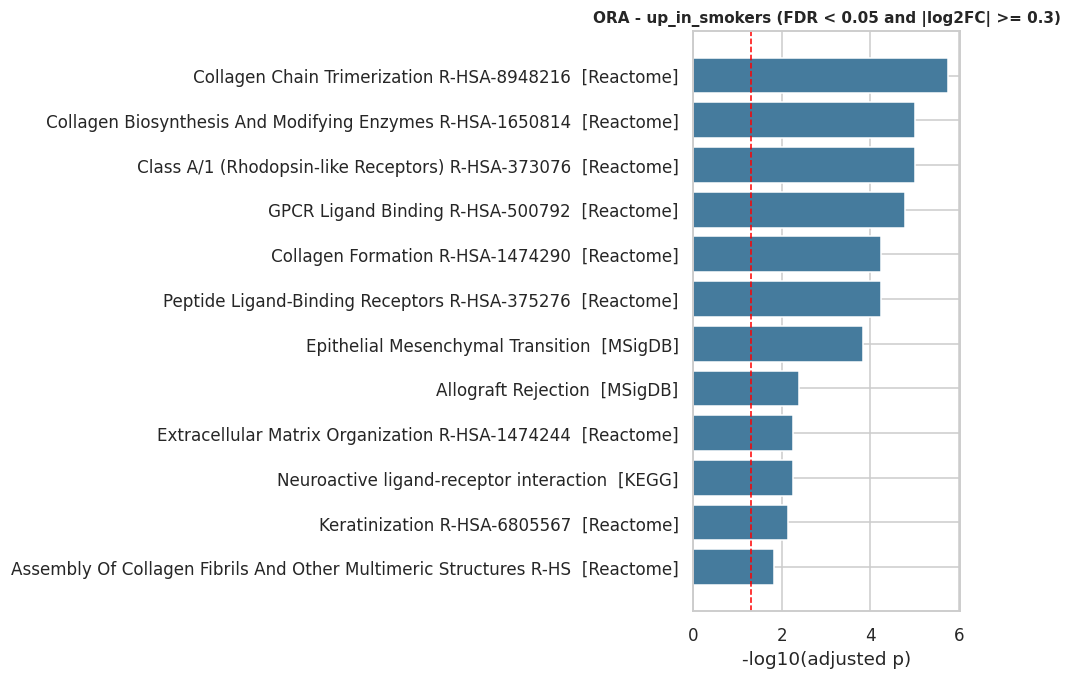

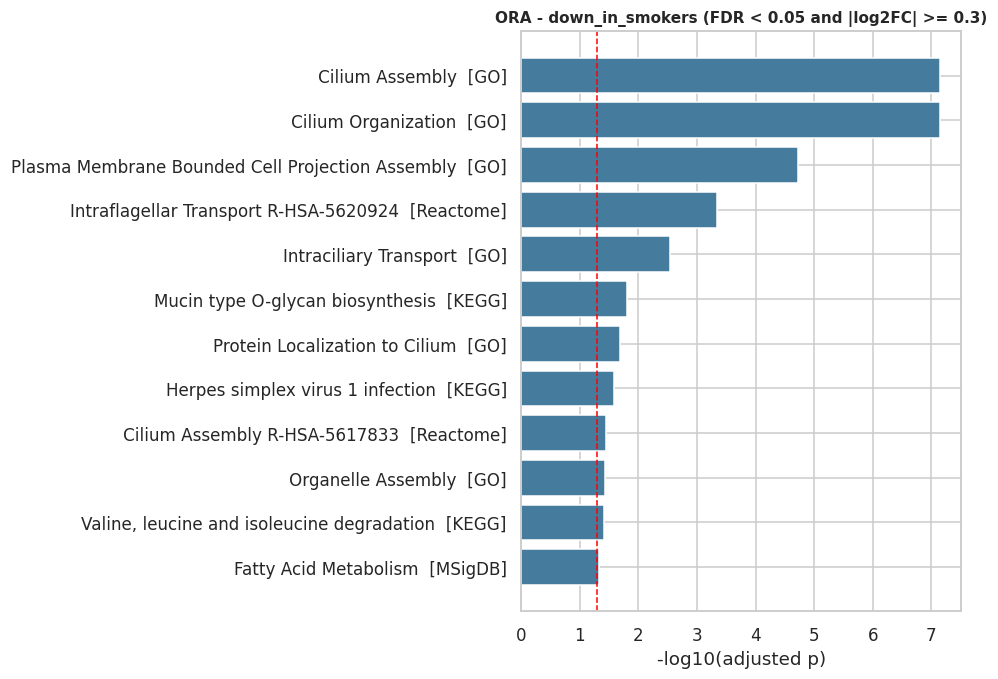

[all_DEGs] no term reaches adjusted p < 0.05; best terms:


,Gene_set,Term,Overlap,P-value,Adjusted P-value
5472,Reactome_2022,Collagen Chain Trimerization R-HSA-8948216,22/44,0.000031,0.051200
5473,Reactome_2022,Collagen Biosynthesis And Modifying Enzymes R-...,28/67,0.000165,0.134425
5474,Reactome_2022,Collagen Formation R-HSA-1474290,34/90,0.000361,0.196247
0,GO_Biological_Process_2026,Photoreceptor Cell Development (GO:0042461),11/21,0.001932,0.999996
5475,Reactome_2022,FGFRL1 Modulation Of FGFR1 Signaling R-HSA-565...,8/13,0.002152,0.878540


In [22]:
def plot_ora(df, title, fname, n=12):
    d = df.sort_values("Adjusted P-value").head(n).copy()
    d["-log10 FDR"] = -np.log10(d["Adjusted P-value"].clip(lower=1e-300))
    d["label"] = d["Term"].str.replace(r" \(GO:\d+\)", "", regex=True).str.slice(0, 65) + "  [" + d["Gene_set"].str.split("_").str[0] + "]"
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(d) + 1.3))
    ax.barh(d["label"][::-1], d["-log10 FDR"][::-1], color="#457b9d")
    ax.axvline(-np.log10(0.05), color="red", ls="--", lw=1)
    ax.set_xlabel("-log10(adjusted p)"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.savefig(fname); plt.show()

if ora_results:
    for label, r in ora_results.items():
        if (r["Adjusted P-value"] < 0.05).any():
            plot_ora(r, f"ORA - {label} ({ORA_BASIS})", f"{OUTDIR}/ora_{label}.png")
        else:
            print(f"[{label}] no term reaches adjusted p < 0.05; best terms:")
            display(r.sort_values("P-value").head(5)[["Gene_set", "Term", "Overlap", "P-value", "Adjusted P-value"]])
else:
    print("ORA results are unavailable (no internet access to Enrichr, or too few genes). GSEA below may still work.")

2026-11-24 08:14:56,752 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-24 08:15:04,293 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


MSigDB_Hallmark_2020: 50 gene sets tested, 21 with FDR q < 0.25, 13 with FDR q < 0.05


2026-11-24 08:15:42,560 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


KEGG_2021_Human: 301 gene sets tested, 44 with FDR q < 0.25, 19 with FDR q < 0.05
Reactome_2022: 1118 gene sets tested, 256 with FDR q < 0.25, 79 with FDR q < 0.05


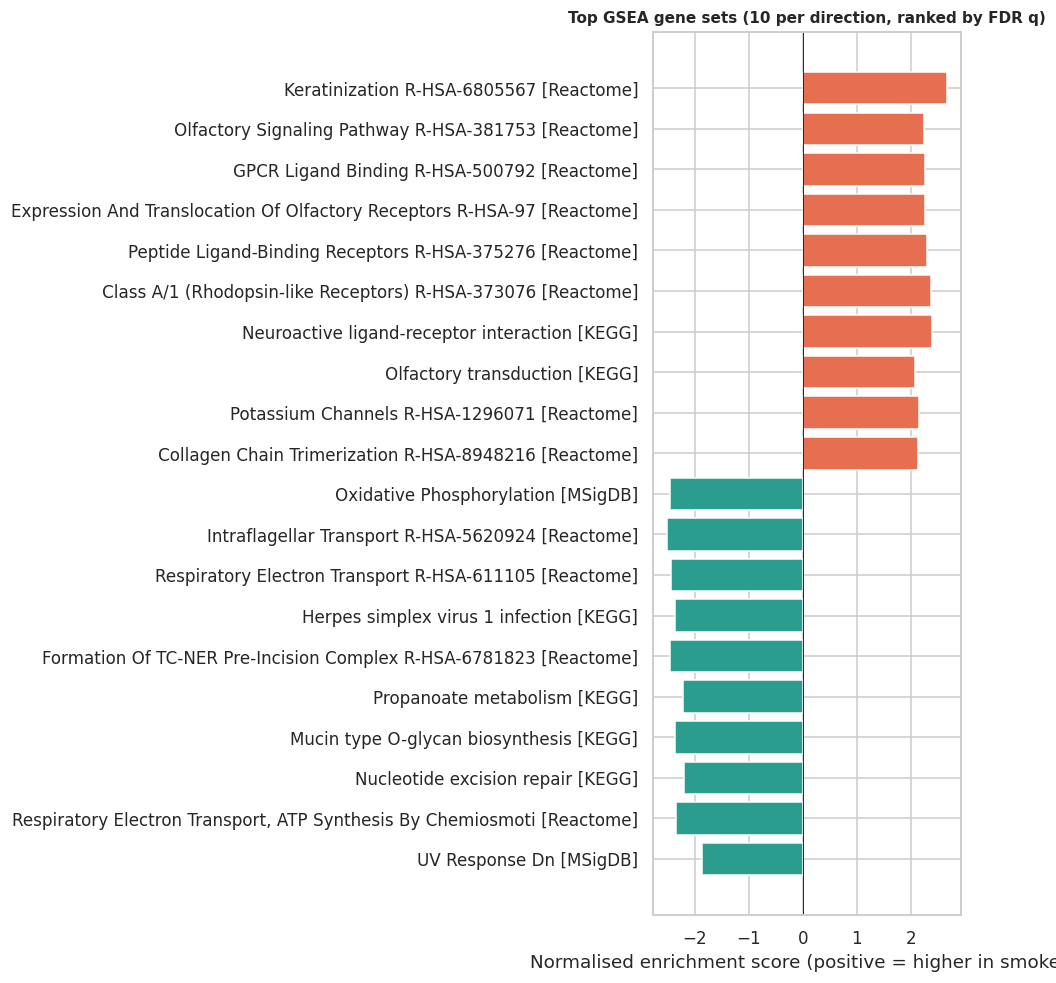

,library,Term,NES,NOM p-val,FDR q-val
0,MSigDB_Hallmark_2020,Oxidative Phosphorylation,-2.4581,0.0,0.0000
352,Reactome_2022,Intraflagellar Transport R-HSA-5620924,-2.5195,0.0,0.0000
351,Reactome_2022,Keratinization R-HSA-6805567,2.6730,0.0,0.0000
362,Reactome_2022,Olfactory Signaling Pathway R-HSA-381753,2.2319,0.0,0.0000
359,Reactome_2022,GPCR Ligand Binding R-HSA-500792,2.2632,0.0,0.0000
360,Reactome_2022,Expression And Translocation Of Olfactory Rece...,2.2594,0.0,0.0000
358,Reactome_2022,Peptide Ligand-Binding Receptors R-HSA-375276,2.2921,0.0,0.0000
355,Reactome_2022,Class A/1 (Rhodopsin-like Receptors) R-HSA-373076,2.3684,0.0,0.0000
50,KEGG_2021_Human,Neuroactive ligand-receptor interaction,2.3808,0.0,0.0000
56,KEGG_2021_Human,Olfactory transduction,2.0762,0.0,0.0000


In [23]:
#  pre-ranked GSEA on all tested genes
rnk = res_primary["t"].sort_values(ascending=False)       # signed statistic: positive = higher in smokers
GSEA_LIBS = [LIBS["Hallmark"], LIBS["KEGG"], LIBS["Reactome"]] + ([LIBS["GO_BP"]] if RUN_GO_GSEA else [])
gsea_results = {}
for lib in GSEA_LIBS:
    try:
        pre = gp.prerank(rnk=rnk, gene_sets=lib, permutation_num=1000, min_size=15, max_size=500, seed=SEED,
                         outdir=None, verbose=False, threads=2, no_plot=True)
        r = pre.res2d.copy()
        for c in ["ES", "NES", "NOM p-val", "FDR q-val"]:
            r[c] = pd.to_numeric(r[c], errors="coerce")
        r["library"] = lib
        gsea_results[lib] = r
        r.sort_values("FDR q-val").to_csv(f"{OUTDIR}/GSEA_{lib}.csv", index=False)
        print(f"{lib}: {len(r)} gene sets tested, {(r['FDR q-val'] < 0.25).sum()} with FDR q < 0.25, {(r['FDR q-val'] < 0.05).sum()} with FDR q < 0.05")
    except Exception as e:
        print(f"GSEA failed for {lib}: {type(e).__name__}: {e}")

if gsea_results:
    allg = pd.concat(gsea_results.values(), ignore_index=True).sort_values("FDR q-val")
    top = pd.concat([allg[allg.NES > 0].head(10), allg[allg.NES < 0].head(10)])
    top = top.assign(label=top["Term"].str.replace(r" \(GO:\d+\)", "", regex=True).str.slice(0, 60) + " [" + top["library"].str.split("_").str[0] + "]")
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(top) + 1.5))
    ax.barh(top["label"][::-1], top["NES"][::-1], color=np.where(top["NES"][::-1] > 0, PALETTE["Smoker"], PALETTE["Never"]))
    ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("Normalised enrichment score (positive = higher in smokers)")
    ax.set_title("Top GSEA gene sets (10 per direction, ranked by FDR q)", fontsize=10)
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/gsea_top_sets.png"); plt.show()
    display(allg.head(15)[["library", "Term", "NES", "NOM p-val", "FDR q-val"]].round(4))
else:
    print("No GSEA results (Enrichr gene-set libraries could not be downloaded).")

## 6. Biological interpretation

The cells below organise the statistical output into biological themes.  The keyword-based theme assignment is a heuristic; check the underlying terms and genes yourself.

How to read the results:
- **A gene being "significant" means its mean expression differs between the groups.** It does not by itself say that smoking caused the change (this is an observational comparison of tumours), nor that the gene matters for tumour biology.
- **logFC is on the log2 scale**: logFC = 0.5 means about 1.41-fold higher in smokers; array data tend to compress fold changes, so small values can still be real.
- **Pathway enrichment tells us which processes the gene set collectively points to.** ORA depends on the gene list cut-off; GSEA uses the full ranking. Agreement between both is more convincing than either alone.

direction,down_in_smokers,up_in_smokers
theme,,
Cell cycle / proliferation / DNA replication,2,0
DNA damage response / repair / p53,16,0
ECM / adhesion / EMT / angiogenesis,1,13
Growth-factor / kinase signalling,33,1
Immune response / inflammation,7,8
Lung development / surfactant / epithelial differentiation,8,2
Metabolism (lipid / glycolysis / OXPHOS),16,0
Other / unclassified,160,85
Oxidative stress / hypoxia / apoptosis,2,0


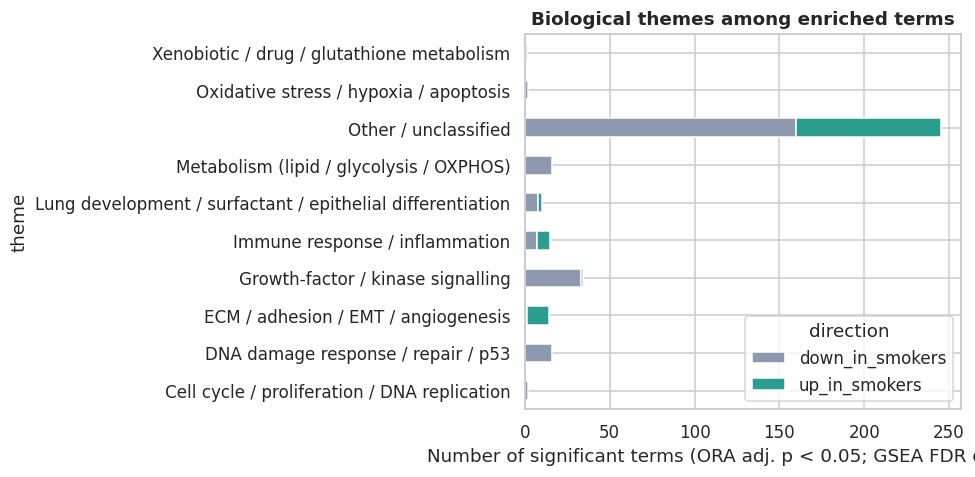

In [24]:
THEMES = {
    "Xenobiotic / drug / glutathione metabolism": r"xenobiotic|cytochrome|drug metabol|glutathione|aryl hydrocarbon|detox|oxidoreductase|quinone|retinol|steroid hormone|UDP|glucuronid",
    "Cell cycle / proliferation / DNA replication": r"cell cycle|mitotic|mitosis|DNA replication|E2F|G2-?M|chromosome|spindle|kinetochore|proliferat|cytokinesis|centromere|MYC",
    "DNA damage response / repair / p53": r"DNA repair|DNA damage|double-strand|p53|homologous recomb|mismatch repair|nucleotide excision|checkpoint",
    "Immune response / inflammation": r"immune|inflammat|interferon|cytokine|TNF|interleukin|IL-?\d|T cell|B cell|leukocyte|complement|antigen|NF-kappa|chemokine|allograft|neutrophil",
    "Oxidative stress / hypoxia / apoptosis": r"oxidative stress|reactive oxygen|hypoxia|apopto|cell death|unfolded protein|response to stress|p38",
    "ECM / adhesion / EMT / angiogenesis": r"extracellular matrix|collagen|adhesion|integrin|epithelial.mesenchymal|angiogen|cell migration|focal adhesion",
    "Growth-factor / kinase signalling": r"MAPK|ERK|PI3K|AKT|mTOR|EGFR|ERBB|KRAS|Ras|Wnt|Notch|Hedgehog|TGF|JAK|STAT|VEGF|receptor tyrosine",
    "Metabolism (lipid / glycolysis / OXPHOS)": r"lipid|fatty acid|glycoly|oxidative phosphorylation|metabolic|cholesterol|TCA|amino acid",
    "Lung development / surfactant / epithelial differentiation": r"surfactant|lung|alveol|epithelial cell differentiation|keratinization|cilium|ciliar",
}

term_rows = []
for label, r in ora_results.items():
    for _, x in r[r["Adjusted P-value"] < 0.05].iterrows():
        term_rows.append({"source": f"ORA:{label}", "library": x["Gene_set"], "term": x["Term"], "stat": x["Adjusted P-value"], "direction": label})
for lib, r in gsea_results.items():
    for _, x in r[r["FDR q-val"] < 0.25].iterrows():
        term_rows.append({"source": "GSEA", "library": lib, "term": x["Term"], "stat": x["FDR q-val"],
                          "direction": "up_in_smokers" if x["NES"] > 0 else "down_in_smokers"})
terms = pd.DataFrame(term_rows)

if len(terms):
    def theme_of(t):
        hits = [k for k, pat in THEMES.items() if re.search(pat, t, flags=re.I)]
        return hits[0] if hits else "Other / unclassified"
    terms["theme"] = terms["term"].map(theme_of)
    tab = terms.groupby(["theme", "direction"]).size().unstack(fill_value=0)
    display(tab)
    terms.sort_values("stat").to_csv(f"{OUTDIR}/enrichment_terms_with_themes.csv", index=False)
    tab.plot(kind="barh", stacked=True, figsize=(9, 4.5), color=["#8d99ae", "#2a9d8f", "#e76f51"][:tab.shape[1]])
    plt.xlabel("Number of significant terms (ORA adj. p < 0.05; GSEA FDR q < 0.25)"); plt.title("Biological themes among enriched terms")
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/interpretation_themes.png"); plt.show()
else:
    print("No terms passed the enrichment thresholds. That is itself a result: smoking status may be associated with only weak or diffuse "
          "expression differences in this cohort. See the exploratory ORA / nominal results above before concluding.")

In [25]:
# which DEGs and leading-edge genes drive the top enriched processes?
if ora_results:
    all_ora = pd.concat(ora_results.values(), ignore_index=True)
    best = all_ora[all_ora["list"] != "all_DEGs"].sort_values("Adjusted P-value").head(8)
    print("Top ORA terms and the DEGs that drive them:\n")
    for _, x in best.iterrows():
        genes = [g for g in str(x["Genes"]).split(";")]
        lfc = res_primary.reindex(genes).logFC.round(2)
        print(f"- [{x['list']}] {x['Term']}  (adj p = {x['Adjusted P-value']:.2g}, overlap {x['Overlap']})")
        print("   genes:", ", ".join(f"{g} ({lfc[g]:+.2f})" for g in genes[:12]), "..." if len(genes) > 12 else "")

if gsea_results:
    allg = pd.concat(gsea_results.values(), ignore_index=True).sort_values("FDR q-val")
    print("\nLeading-edge genes of the top GSEA sets:\n")
    for _, x in allg.head(6).iterrows():
        lead = str(x["Lead_genes"]).split(";")[:15]
        print(f"- {x['Term']} [{x['library']}]  NES = {x['NES']:+.2f}, FDR q = {x['FDR q-val']:.3g}")
        print("   leading edge:", ", ".join(lead))

Top ORA terms and the DEGs that drive them:

- [down_in_smokers] Cilium Organization (GO:0044782)  (adj p = 7e-08, overlap nan)
   genes: SPAG16 (-0.45), IFT172 (-0.36), CCP110 (-0.68), FNBP1L (-0.33), CDC14A (-0.41), CDC14B (-0.41), RPGR (-0.37), TCTN1 (-0.33), BBS9 (-0.34), NEK1 (-0.36), IFT57 (-0.63), BBS5 (-0.55) ...
- [down_in_smokers] Cilium Assembly (GO:0060271)  (adj p = 7e-08, overlap nan)
   genes: SPAG16 (-0.45), SPAG17 (-1.26), GORAB (-0.38), IFT172 (-0.36), FNBP1L (-0.33), CDC14A (-0.41), CDC14B (-0.41), RPGR (-0.37), TBC1D32 (-0.52), TCTN1 (-0.33), BBS9 (-0.34), NEK1 (-0.36) ...
- [up_in_smokers] Collagen Chain Trimerization R-HSA-8948216  (adj p = 1.8e-06, overlap 21/44)
   genes: COL15A1 (+0.57), COL26A1 (+0.44), COL16A1 (+0.37), COL25A1 (+0.57), COL11A1 (+0.85), COL22A1 (+0.31), COL11A2 (+0.34), COL23A1 (+0.30), COL19A1 (+0.31), COL1A1 (+0.76), COL3A1 (+0.89), COL1A2 (+0.71) ...
- [up_in_smokers] Collagen Biosynthesis And Modifying Enzymes R-HSA-1650814  (adj p = 9.8e-

## 7. Machine learning (supplementary analysis, Objective 3)

**Question:** can a tumour's expression profile predict whether the patient smoked?

This is supplementary: DE tells us *which* genes differ; ML asks whether the differences are strong and consistent enough to **classify individual tumours** in samples the model has never seen. With 80 samples and ~15,000 features, the main risk is **overfitting and information leakage**, so the design is deliberately conservative:

- **Nested cross-validation.** The outer loop (5-fold x 3 repeats, stratified) estimates performance on held-out tumours; the inner loop (3-fold) tunes hyper-parameters *only on the training part* of each outer fold.
- **Feature selection happens inside the pipeline** (`SelectKBest` on the training fold only). Selecting genes on all 80 samples before cross-validation would leak label information and inflate the AUC; we demonstrate this effect below.
- **Metrics:** ROC-AUC (threshold-free; 0.5 = chance) and balanced accuracy (robust to class imbalance).
- **Controls:** (i) label-permutation test for significance, (ii) covariate-only baseline (does sex/age alone predict smoking?), (iii) unsupervised clustering.
- Three model families of increasing flexibility: L2-logistic regression, linear SVM, random forest.

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, permutation_test_score, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, adjusted_rand_score
from sklearn.cluster import KMeans

X = expr_t.T.values.astype(float)               # samples x genes (log2 RMA values, untouched)
gene_names = np.array(expr_t.index)
y = (pheno_t["smoking"] == "Smoker").astype(int).values
print(f"Feature matrix: {X.shape[0]} tumours x {X.shape[1]} genes | smokers = {y.sum()}, never-smokers = {(1 - y).sum()}")

def make_pipe(clf):
    return Pipeline([("select", SelectKBest(f_classif, k=200)), ("scale", StandardScaler()), ("clf", clf)])

K_GRID = [50, 200, 1000]
MODELS = {
    "Logistic regression (L2)": (LogisticRegression(max_iter=5000), {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "Linear SVM": (SVC(kernel="linear"), {"clf__C": [0.001, 0.01, 0.1, 1]}),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), {"clf__min_samples_leaf": [1, 3]}),
}
N_SPLITS, N_REPEATS = 5, 3
outer_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
mean_fpr = np.linspace(0, 1, 101)

def nested_cv(name, clf, grid):
    pipe = make_pipe(clf)
    param_grid = {"select__k": K_GRID, **grid}
    folds, tprs = [], []
    sel_count = np.zeros(X.shape[1]); coef_sum = np.zeros(X.shape[1])
    oof_true, oof_pred = [], []
    for i, (tr, te) in enumerate(outer_cv.split(X, y)):
        gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED + i), scoring="roc_auc", n_jobs=-1)
        gs.fit(X[tr], y[tr])
        score = gs.decision_function(X[te]) if hasattr(gs, "decision_function") else gs.predict_proba(X[te])[:, 1]
        pred = gs.predict(X[te])
        auc = roc_auc_score(y[te], score)
        fpr, tpr, _ = roc_curve(y[te], score)
        tprs.append(np.interp(mean_fpr, fpr, tpr)); tprs[-1][0] = 0.0
        folds.append({"model": name, "repeat": i // N_SPLITS, "fold": i % N_SPLITS, "AUC": auc,
                      "balanced_accuracy": balanced_accuracy_score(y[te], pred), **{f"best_{k}": v for k, v in gs.best_params_.items()}})
        support = gs.best_estimator_.named_steps["select"].get_support()
        sel_count += support
        fitted = gs.best_estimator_.named_steps["clf"]
        if hasattr(fitted, "coef_"):
            coef_sum[support] += np.asarray(fitted.coef_).ravel()
        elif hasattr(fitted, "feature_importances_"):
            coef_sum[support] += fitted.feature_importances_
        if i < N_SPLITS:                                  # first repeat = a full out-of-fold partition
            oof_true.extend(y[te]); oof_pred.extend(pred)
    return pd.DataFrame(folds), np.array(tprs), sel_count, coef_sum, (np.array(oof_true), np.array(oof_pred))

cv_results, cv_tprs, cv_sel, cv_coef, cv_oof = {}, {}, {}, {}, {}
for name, (clf, grid) in MODELS.items():
    print("Running nested CV:", name)
    cv_results[name], cv_tprs[name], cv_sel[name], cv_coef[name], cv_oof[name] = nested_cv(name, clf, grid)

perf = pd.concat(cv_results.values(), ignore_index=True)
perf_summary = perf.groupby("model").agg(AUC_mean=("AUC", "mean"), AUC_sd=("AUC", "std"),
                                          bAcc_mean=("balanced_accuracy", "mean"), bAcc_sd=("balanced_accuracy", "std")).round(3)
display(perf_summary)
perf.to_csv(f"{OUTDIR}/ml_nested_cv_fold_results.csv", index=False)

Feature matrix: 80 tumours x 18645 genes | smokers = 40, never-smokers = 40
Running nested CV: Logistic regression (L2)
Running nested CV: Linear SVM
Running nested CV: Random forest


,AUC_mean,AUC_sd,bAcc_mean,bAcc_sd
model,,,,
Linear SVM,1.000,0.000,0.996,0.016
Logistic regression (L2),0.996,0.009,0.975,0.040
Random forest,0.984,0.026,0.917,0.065


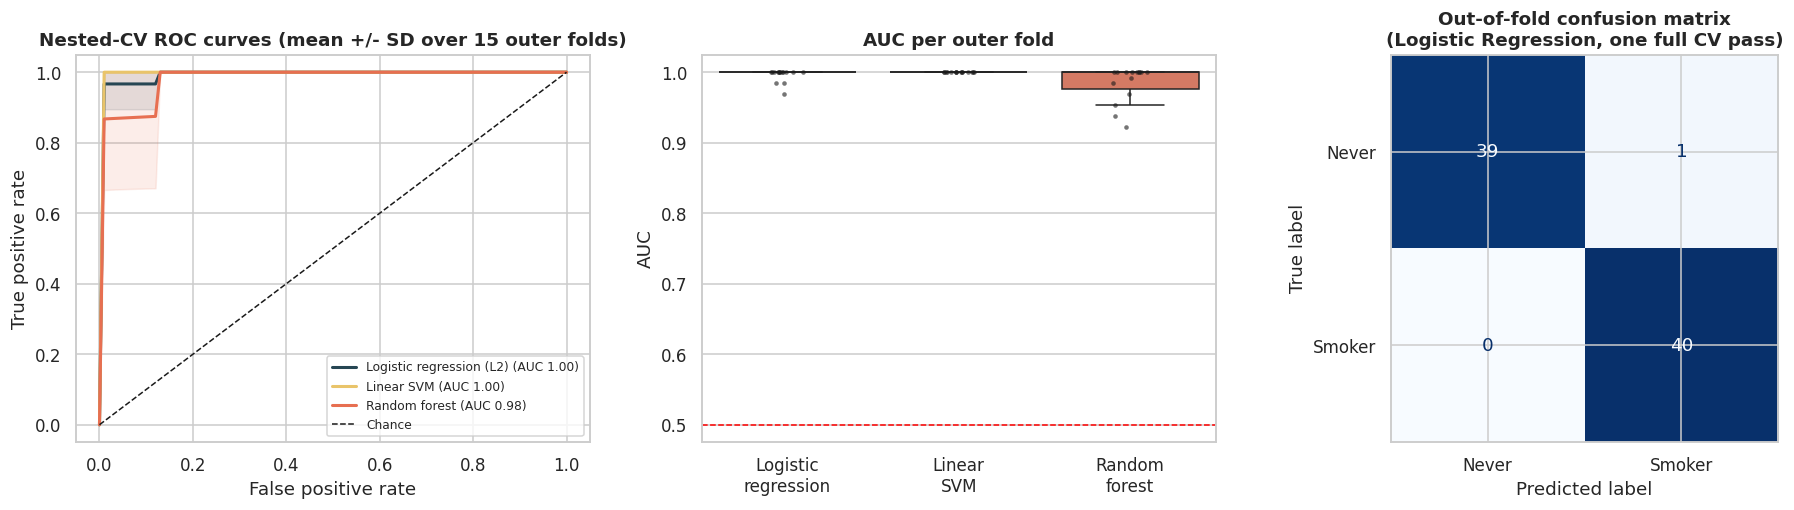

Best model by mean nested-CV AUC: Linear SVM


In [27]:
# performance plotS
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cols = {"Logistic regression (L2)": "#264653", "Linear SVM": "#e9c46a", "Random forest": "#e76f51"}
for name, tp in cv_tprs.items():
    m, s = tp.mean(axis=0), tp.std(axis=0)
    m[-1] = 1.0
    ax[0].plot(mean_fpr, m, color=cols[name], lw=2, label=f"{name} (AUC {perf_summary.loc[name,'AUC_mean']:.2f})")
    ax[0].fill_between(mean_fpr, np.clip(m - s, 0, 1), np.clip(m + s, 0, 1), color=cols[name], alpha=0.12)
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("Nested-CV ROC curves (mean +/- SD over 15 outer folds)"); ax[0].legend(fontsize=8, loc="lower right")

sns.boxplot(data=perf, x="model", y="AUC", hue="model", order=list(MODELS), hue_order=list(MODELS), palette=cols, legend=False, ax=ax[1], showfliers=False)
sns.stripplot(data=perf, x="model", y="AUC", order=list(MODELS), color="k", size=3, alpha=0.6, ax=ax[1])
ax[1].axhline(0.5, color="red", ls="--", lw=1); ax[1].set_xticks(range(len(MODELS)))
ax[1].set_xticklabels([m.replace(" (L2)", "").replace(" ", "\n") for m in MODELS])
ax[1].set_title("AUC per outer fold"); ax[1].set_xlabel("")

best_model = perf_summary["AUC_mean"].idxmax()
yt, yp = cv_oof[best_model]
ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=["Never", "Smoker"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"Out-of-fold confusion matrix\n(Logistic Regression, one full CV pass)")
plt.tight_layout(); plt.savefig(f"{OUTDIR}/ml_performance.png"); plt.show()
print("Best model by mean nested-CV AUC:", best_model)

### 7.1 Is the performance better than chance? Permutation test, baselines and a leakage demonstration

Permutation test (logistic, k=200, C=0.01): AUC = 0.975; permuted mean AUC = 0.528; p = 0.0099


,labels,leaky CV (select genes first),proper CV (select inside folds)
0,real,0.981,0.975
1,randomly shuffled (no true signal),0.891,0.469


With shuffled labels the proper pipeline stays near 0.5 while the leaky one looks 'predictive': this is why selection is nested.


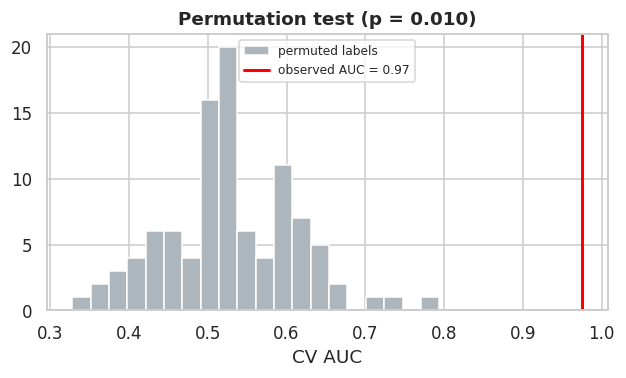

In [28]:
# (1) permutation test with a fixed, reasonable configuration (L2-logistic, k=200, C=0.01) - 5-fold CV
pipe_fixed = make_pipe(LogisticRegression(C=0.01, max_iter=5000))
score_true, perm_scores, pval = permutation_test_score(
    pipe_fixed, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc",
    n_permutations=N_PERM_ML, n_jobs=-1, random_state=SEED)
print(f"Permutation test (logistic, k=200, C=0.01): AUC = {score_true:.3f}; permuted mean AUC = {perm_scores.mean():.3f}; p = {pval:.4f}")

# (2) covariate-only baseline: do sex/age alone separate smokers from never-smokers?
base_auc = None
if ADJUST_FOR:
    Xcov = pd.get_dummies(pheno_t[ADJUST_FOR], drop_first=True).astype(float)
    Xcov = Xcov.fillna(Xcov.median()).values
    base = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
    base_auc = np.mean([cross_val_score(base, Xcov, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r), scoring="roc_auc").mean() for r in range(10)])
    print(f"Covariate-only model ({', '.join(ADJUST_FOR)}): mean CV AUC = {base_auc:.3f}")
    print("-> If this is well above 0.5, part of any expression-based performance may reflect sex/age confounding rather than smoking biology.")

# (3) leakage demonstration: select genes on ALL samples first, then cross-validate
def leaky_auc(yv):
    Xs = SelectKBest(f_classif, k=200).fit_transform(X, yv)            # uses every label -> leakage
    p = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=0.01, max_iter=5000))])
    return cross_val_score(p, Xs, yv, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()

def proper_auc(yv):
    return cross_val_score(make_pipe(LogisticRegression(C=0.01, max_iter=5000)), X, yv,
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()

y_shuffled = np.random.default_rng(SEED).permutation(y)
leak_demo = pd.DataFrame({"labels": ["real", "randomly shuffled (no true signal)"],
                          "leaky CV (select genes first)": [leaky_auc(y), leaky_auc(y_shuffled)],
                          "proper CV (select inside folds)": [proper_auc(y), proper_auc(y_shuffled)]}).round(3)
display(leak_demo)
print("With shuffled labels the proper pipeline stays near 0.5 while the leaky one looks 'predictive': this is why selection is nested.")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(perm_scores, bins=20, color="#adb5bd", edgecolor="white", label="permuted labels")
ax.axvline(score_true, color="red", lw=2, label=f"observed AUC = {score_true:.2f}")
if base_auc: ax.axvline(base_auc, color="blue", ls="--", lw=1.5, label=f"covariates only = {base_auc:.2f}")
ax.set_xlabel("CV AUC"); ax.set_title(f"Permutation test (p = {pval:.3f})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUTDIR}/ml_permutation_test.png"); plt.show()

### 7.2 Which genes does the classifier rely on, and do they match the DE genes?
For each model we recorded, across the 15 outer folds, how often each gene was selected and its (standardised) coefficient. Genes selected in most folds form a *stable signature*. We then ask whether that signature overlaps the DE genes more than expected by chance (hypergeometric test). These coefficients are **descriptive**; the unbiased performance estimate is the nested CV above.

Genes selected in >= 80% of outer folds: 667


,selection_freq,mean_std_coef,DE_logFC,DE_FDR
ACTL7B,1.0,0.002,0.478,0.0
KRT84,1.0,0.032,0.407,0.0
NOS2P1,1.0,0.023,0.527,0.0
TMEM179,1.0,0.014,0.399,0.0
PRAMEF25,1.0,0.053,0.470,0.0
RN7SL335P,1.0,0.012,0.576,0.0
OR13J1,1.0,0.057,0.500,0.0
RNA5SP32,1.0,0.008,0.596,0.0
KRTAP13-4,1.0,0.057,0.465,0.0
RN7SL601P,1.0,0.032,0.496,0.0



Overlap between stable ML genes (667) and DE genes with p < 0.01 (7295): 667 genes; hypergeometric p = 5.81e-281


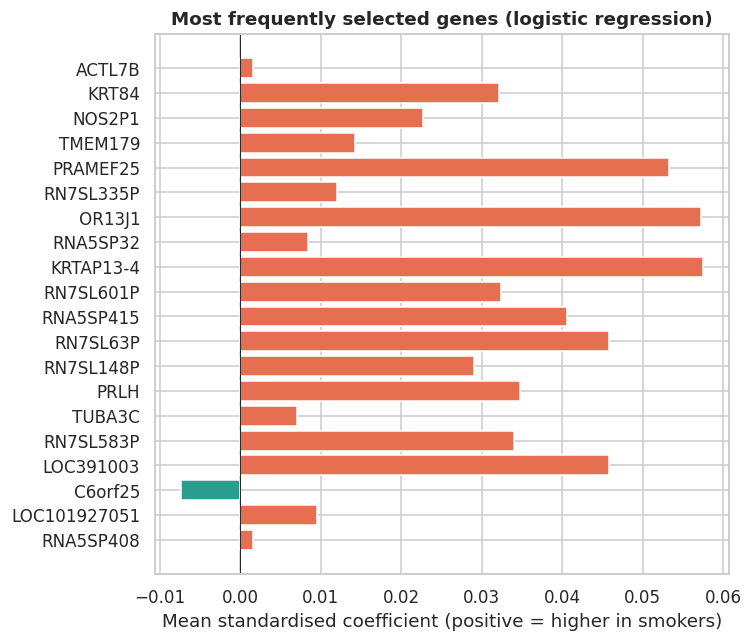

In [29]:
n_outer = N_SPLITS * N_REPEATS
lr_name = "Logistic regression (L2)"
freq = pd.Series(cv_sel[lr_name] / n_outer, index=gene_names)
mean_coef = pd.Series(np.where(cv_sel[lr_name] > 0, cv_coef[lr_name] / np.maximum(cv_sel[lr_name], 1), 0), index=gene_names)
stable = pd.DataFrame({"selection_freq": freq, "mean_std_coef": mean_coef}).sort_values("selection_freq", ascending=False)
stable["DE_logFC"] = res_primary["logFC"].reindex(stable.index)
stable["DE_FDR"] = res_primary["FDR"].reindex(stable.index)
stable.to_csv(f"{OUTDIR}/ml_stable_genes_logistic.csv")

stable_genes = stable.index[stable.selection_freq >= 0.8]
print(f"Genes selected in >= 80% of outer folds: {len(stable_genes)}")
display(stable.head(20).round(3))

# overlap with DE hits (nominal p < 0.01 so the comparison is informative even if few genes pass FDR)
de_set = set(res_primary.index[res_primary.P < 0.01])
M, K, n = len(gene_names), len(de_set), len(stable_genes)
k = len(de_set & set(stable_genes))
p_hyp = stats.hypergeom.sf(k - 1, M, K, n) if n and K else np.nan
print(f"\nOverlap between stable ML genes ({n}) and DE genes with p < 0.01 ({K}): {k} genes; hypergeometric p = {p_hyp:.3g}")

top = stable.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["mean_std_coef"], color=np.where(top["mean_std_coef"] > 0, PALETTE["Smoker"], PALETTE["Never"]))
ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("Mean standardised coefficient (positive = higher in smokers)")
ax.set_title("Most frequently selected genes (logistic regression)"); plt.tight_layout(); plt.savefig(f"{OUTDIR}/ml_stable_genes.png"); plt.show()

### 7.3 Unsupervised check: do tumours cluster by smoking status without being told?
K-means (k = 2) on the first 10 principal components of the tumours. The adjusted Rand index (ARI) measures agreement with the smoking labels (0 = random, 1 = perfect). We also compare with sex, to see what the dominant unsupervised structure actually reflects.

In [30]:
Xc = X - X.mean(axis=0)
pcs = PCA(n_components=10, random_state=SEED).fit_transform(Xc)
km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(pcs)
ari_smoke = adjusted_rand_score(y, km.labels_)
print(f"ARI (clusters vs smoking status) = {ari_smoke:.3f}")
display(pd.crosstab(pd.Series(km.labels_, name="cluster"), pheno_t["smoking"].values))
if "sex_final" in pheno_t:
    ari_sex = adjusted_rand_score(pheno_t["sex_final"].values, km.labels_)
    print(f"ARI (clusters vs sex) = {ari_sex:.3f}")
if ari_smoke < 0.1:
    print("ARI near 0: smoking status is not the dominant axis of variation in the tumours (consistent with a subtle signal).")
elif ari_smoke < 0.4:
    print("Modest agreement: smoking explains part of the dominant structure, but other factors (e.g. sex, histology, purity) matter too.")
else:
    print("Strong agreement: smoking status is a major axis of variation - check that it is not driven by a confounder such as sex.")

ARI (clusters vs smoking status) = 0.415


col_0,Never,Smoker
cluster,,
0,33,7
1,7,33


Strong agreement: smoking status is a major axis of variation - check that it is not driven by a confounder such as sex.


### 7.4 How to interpret the ML result
- **AUC ~ 0.5** (and a non-significant permutation test): expression alone cannot separate the groups. This is a valid, informative negative result and is consistent with few/small DE effects.
- **AUC well above 0.5 and permutation p < 0.05**: expression carries real information about smoking history, but check the covariate-only baseline: if sex or age alone give a similar AUC, the model may be learning confounders.
- **Moderate AUC (0.6-0.75)** is typical for subtle biological differences with n = 80; it does not make the model a clinical tool. With only one cohort and no external validation, the estimate is optimistic relative to a truly independent dataset.
- Agreement between the stable ML genes and the DE genes (7.2) supports a consistent set of smoking-associated genes; disagreement is expected when signals are weak, since the two approaches optimise different criteria.

## 8. Summary, limitations and export

In [31]:
summary = {
    "dataset": GSE_ID,
    "n_tumours": int(len(pheno_t)), "n_smokers": int((pheno_t.smoking == "Smoker").sum()), "n_never_smokers": int((pheno_t.smoking == "Never").sum()),
    "genes_tested": int(res_primary.shape[0]),
    "primary_model": PRIMARY_LABEL,
    "DE_genes_FDR_0.05": int((res_primary.FDR < 0.05).sum()),
    "DE_up_in_smokers": int(((res_primary.FDR < 0.05) & (res_primary.logFC > 0)).sum()),
    "DE_down_in_smokers": int(((res_primary.FDR < 0.05) & (res_primary.logFC < 0)).sum()),
    "DE_genes_FDR_0.10": int((res_primary.FDR < 0.10).sum()),
    "permutation_global_p": float(emp_p),
    "top_DE_genes": res_primary.index[:10].tolist(),
    "enrichment_ORA_basis": ORA_BASIS,
    "ORA_significant_terms": {k: int((v["Adjusted P-value"] < 0.05).sum()) for k, v in ora_results.items()},
    "GSEA_sets_FDR_0.25": {k: int((v["FDR q-val"] < 0.25).sum()) for k, v in gsea_results.items()},
    "ML_best_model": best_model,
    "ML_nested_CV_AUC": perf_summary["AUC_mean"].to_dict(),
    "ML_permutation_p": float(pval),
    "ML_covariate_only_AUC": None if base_auc is None else float(base_auc),
    "kmeans_ARI_vs_smoking": float(ari_smoke),
}
with open(f"{OUTDIR}/summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset": "GSE43458",
  "n_tumours": 80,
  "n_smokers": 40,
  "n_never_smokers": 40,
  "genes_tested": 18645,
  "primary_model": "Model A (unadjusted)",
  "DE_genes_FDR_0.05": 8332,
  "DE_up_in_smokers": 4835,
  "DE_down_in_smokers": 3497,
  "DE_genes_FDR_0.10": 9683,
  "permutation_global_p": 0.004975124378109453,
  "top_DE_genes": [
    "MCCD1",
    "RN7SL583P",
    "OR13J1",
    "RN7SL771P",
    "LOC391003",
    "IGLJCOR18",
    "OPN1MW",
    "NEU2",
    "RN7SL63P",
    "RNA5SP200"
  ],
  "enrichment_ORA_basis": "FDR < 0.05 and |log2FC| >= 0.3",
  "ORA_significant_terms": {
    "up_in_smokers": 20,
    "down_in_smokers": 14,
    "all_DEGs": 0
  },
  "GSEA_sets_FDR_0.25": {
    "MSigDB_Hallmark_2020": 21,
    "KEGG_2021_Human": 44,
    "Reactome_2022": 256
  },
  "ML_best_model": "Linear SVM",
  "ML_nested_CV_AUC": {
    "Linear SVM": 1.0,
    "Logistic regression (L2)": 0.996,
    "Random forest": 0.984
  },
  "ML_permutation_p": 0.009900990099009901,
  "ML_covariate_only_AUC":

### Limitations to state in your report
- **Cohort size:** 40 vs 40 tumours gives power only for moderate-to-large effects; non-significant results do not prove absence of differences.
- **Smoking definition:** the comparison is "ever-smoker" vs "never-smoker" as encoded in GEO. If current, former and heavy/light smokers are pooled, true dose- and time-dependent effects are diluted. Pack-years and time since quitting are not part of this analysis unless present in the metadata.
- **Confounding:** smoking status is associated with sex, age, ethnicity, tumour stage and driver mutations (e.g. *EGFR*, *KRAS*). Only the covariates present in the metadata can be adjusted for; residual confounding remains.
- **Tissue heterogeneity:** bulk tumour expression mixes cancer cells, stroma and immune cells; differences may reflect cell composition (tumour purity) rather than cancer-cell-intrinsic programmes.
- **Platform:** Affymetrix Gene ST arrays have a limited dynamic range (compressed fold changes) and one gene's probe set was chosen to represent each gene symbol.
- **Normal samples** were paired only with a subset of never-smoker cases, so tumour-vs-normal was used only as a pipeline sanity check.
- **Enrichment** depends on gene-set library versions and on the gene-list definition; Enrichr library names may change over time.
- **ML** is trained on a single cohort with nested CV; no external validation dataset was used.
- **Multiple testing** was controlled with BH-FDR; the "known smoking genes" analysis is a targeted look at a pre-specified list, not a new discovery step.
